# HW2 — Classifying Rice Variety with Logistic Regression
**FRA503 Introduction to Machine Learning (1/2569)**

*Phattanarat Jeedjeen 68340700410*

---


## Table of contents
- [1. Problem statement](#1--problem-statement)
- [2. Data loading & quality audit](#2--data-loading--quality-audit)
- [3. Train / test split](#3--train--test-split)
- [4. Target distribution](#4--target-distribution)
- [5. Initial feature exploration](#5--initial-feature-exploration)
- [6. Outlier analysis](#6--outlier-analysis)
- [7. Missing-value analysis](#7--missing-value-analysis)
- [8. Feature selection — continuous features](#8--feature-selection--continuous-features)
- [9. Feature selection — categorical features](#9--feature-selection--categorical-features)
- [10. Redundant-feature analysis](#10--redundant-feature-analysis)
- [11. Feature extraction](#11--feature-extraction)
- [12. Data pre-processing](#12--data-pre-processing)
- [13. Model building & training](#13--model-building-and-training)
- [14. Results and presentation](#14--results-and-presentation)
- [15. Discussion](#15--discussion)
- [16. Conclusion](#16--conclusion)

In [39]:
%matplotlib inline
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

SEED = 42
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 60); pd.set_option('display.max_rows', 100)
def _fmt(v):
    if v != v: return 'nan'
    if v == 0: return '0'
    if abs(v) < 1e-4: return f'{v:.2e}'
    if abs(v) >= 1e5: return f'{v:,.0f}'
    return f'{v:,.4f}'.rstrip('0').rstrip('.') if abs(v) < 1000 else f'{v:,.2f}'.rstrip('0').rstrip('.')
pd.set_option('display.float_format', _fmt)

BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREY, INK = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#8a8a85', '#0b0b0b'
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e4e3de', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.prop_cycle': plt.cycler(color=[BLUE, ORANGE, AQUA, YELLOW, MAGENTA]),
    'axes.titlesize': 10, 'axes.labelsize': 9, 'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.frameon': False, 'legend.fontsize': 8, 'figure.autolayout': False})
print('setup ok  | numpy', np.__version__, '| pandas', pd.__version__)

setup ok  | numpy 1.26.4 | pandas 2.1.4


# 1 · Problem statement

### 1.1 Data description
The Paddy dataset (UCI ML Repository, DOI 10.24432/C55W3J, CC BY 4.0) holds rice-cultivation records from six agri-blocks. Each record covers the plot (size, block, soil type), the rice variety planted, nursery and land preparation, the amounts of fertiliser, herbicide and pesticide applied on given days, the weather in each growth window (rainfall and an "AI" variable, min/max temperature, wind speed/direction, relative humidity), and two harvest measurements: `Trash` (bundles) and `Paddy yield` (kg).

## Variable description
**Role** column: **T** = target, **P** = candidate predictor.

| # | Feature | Role | Type | Definition |
|---|---|---|---|---|
| 1 | `Hectares` | P | Numerical (Integer) | Plot size, in hectares |
| 2 | `Agriblock` | P | Categorical | Agricultural block / district where the plot is located |
| 3 | **`Variety`** | **T** | **Categorical (3 classes)** | **Rice variety planted: `CO_43`, `ponmani`, `delux ponni`** |
| 4 | `Soil Types` | P | Categorical | Soil type, e.g. alluvial or clay |
| 5 | `Seedrate (in Kg)` | P | Numerical (Integer) | Seed quantity used, in kg |
| 6 | `LP_Mainfield (in Tonnes)` | P | Numerical (Continuous) | Land-preparation material/manure used in the main field, in tonnes; exact material not specified |
| 7 | `Nursery` | P | Categorical | Nursery preparation method, e.g. dry or wet |
| 8 | `Nursery area (Cents)` | P | Numerical (Integer) | Nursery area, in cents |
| 9 | `LP_nurseryarea (in Tonnes)` | P | Numerical (Integer) | Manure used to prepare the nursery area, in tonnes |
| 10 | `DAP_20days` | P | Numerical (Integer) | DAP fertiliser applied around day 20 |
| 11 | `Weed28D_thiobencarb` | P | Numerical | Thiobencarb herbicide applied around day 28 |
| 12 | `Urea_40Days` | P | Numerical (Continuous) | Urea fertiliser applied around day 40 |
| 13 | `Potassh_50Days` | P | Numerical (Continuous) | Potash/potassium fertiliser applied around day 50 |
| 14 | `Micronutrients_70Days` | P | Numerical | Micronutrients applied around day 70 |
| 15 | `Pest_60Day (in ml)` | P | Numerical | Pesticide applied around day 60, in ml |
| 16 | `30DRain (in mm)` | P | Numerical (Continuous) | Rainfall in roughly the first 30 days, in mm |
| 17 | `30DAI (in mm)` | P | Numerical (Continuous) | "AI" variable for the first 30 days, in mm; not defined by the source |
| 18 | `30_50DRain (in mm)` | P | Numerical (Continuous) | Rainfall on days 30-50, in mm |
| 19 | `30_50DAI (in mm)` | P | Numerical (Continuous) | "AI" for days 30-50, in mm; undefined |
| 20 | `51_70DRain (in mm)` | P | Numerical (Continuous) | Rainfall on days 51-70, in mm |
| 21 | `51_70AI (in mm)` | P | Numerical (Continuous) | "AI" for days 51-70, in mm; undefined |
| 22 | `71_105DRain (in mm)` | P | Numerical (Continuous) | Rainfall on days 71-105, in mm |
| 23 | `71_105DAI (in mm)` | P | Numerical (Continuous) | "AI" for days 71-105, in mm; undefined |
| 24 | `Min temp_D1_D30` | P | Numerical (Continuous) | Minimum temperature, days 1-30 |
| 25 | `Max temp_D1_D30` | P | Numerical (Continuous) | Maximum temperature, days 1-30 |
| 26 | `Min temp_D31_D60` | P | Numerical (Continuous) | Minimum temperature, days 31-60 |
| 27 | `Max temp_D31_D60` | P | Numerical (Continuous) | Maximum temperature, days 31-60 |
| 28 | `Min temp_D61_D90` | P | Numerical (Continuous) | Minimum temperature, days 61-90 |
| 29 | `Max temp_D61_D90` | P | Numerical (Continuous) | Maximum temperature, days 61-90 |
| 30 | `Min temp_D91_D120` | P | Numerical (Continuous) | Minimum temperature, days 91-120 |
| 31 | `Max temp_D91_D120` | P | Numerical (Continuous) | Maximum temperature, days 91-120 |
| 32 | `Inst Wind Speed_D1_D30 (in Knots)` | P | Numerical | Instantaneous wind speed, days 1-30, in knots |
| 33 | `Inst Wind Speed_D31_D60 (in Knots)` | P | Numerical | Instantaneous wind speed, days 31-60, in knots |
| 34 | `Inst Wind Speed_D61_D90 (in Knots)` | P | Numerical | Instantaneous wind speed, days 61-90, in knots |
| 35 | `Inst Wind Speed_D91_D120 (in Knots)` | P | Numerical | Instantaneous wind speed, days 91-120, in knots |
| 36 | `Wind Direction_D1_D30` | P | Categorical | Wind direction, days 1-30, e.g. SW, NW, ENE, W |
| 37 | `Wind Direction_D31_D60` | P | Categorical | Wind direction, days 31-60 |
| 38 | `Wind Direction_D61_D90` | P | Categorical | Wind direction, days 61-90 |
| 39 | `Wind Direction_D91_D120` | P | Categorical | Wind direction, days 91-120 |
| 40 | `Relative Humidity_D1_D30` | P | Numerical (Continuous) | Relative humidity, days 1-30 |
| 41 | `Relative Humidity_D31_D60` | P | Numerical (Continuous) | Relative humidity, days 31-60 |
| 42 | `Relative Humidity_D61_D90` | P | Numerical (Continuous) | Relative humidity, days 61-90 |
| 43 | `Relative Humidity_D91_D120` | P | Numerical (Continuous) | Relative humidity, days 91-120 |
| 44 | `Trash (in bundles)` | P | Numerical (Integer) | Quantity of "Trash" counted at harvest, in bundles; exact material not specified |
| 45 | `Paddy yield (in Kg)` | P | Numerical (Integer) | Total paddy yield at harvest, in kg |

### 1.2 Problem definition
| Topic | Definition |
|---|---|
| **General problem** | Agricultural agencies collect season records from many farms, but the variety field is often missing or wrong. **Goal:** given a plot's complete season record, identify which rice variety was grown, to fill in or check the variety label. |
| **ML problem** | **Supervised multiclass classification**. Learn $f:\mathbf{x}\rightarrow \hat y$, where $\hat y$ is one of `CO_43`, `delux ponni`, `ponmani`, with **logistic regression**. The multiclass problem is solved with **One-vs-Rest (OvR)**: $K = 3$ independent **binary** logistic-regression models, one per variety, each separating *that variety* (label 1) from *the other two* (label 0). Model $k$ outputs $p_k(\mathbf{x}) = \sigma(\mathbf{w}_k^\top\mathbf{x}+b_k) = \dfrac{1}{1+e^{-(\mathbf{w}_k^\top\mathbf{x}+b_k)}}$, the probability that the plot grew variety $k$, and is fit by minimising its binary cross-entropy $-\frac{1}{n}\sum_i \big[y_{ik}\log p_k(\mathbf{x}_i) + (1-y_{ik})\log(1-p_k(\mathbf{x}_i))\big]$. Prediction: $\hat y = \arg\max_k p_k(\mathbf{x})$, the variety whose model is most confident. The 3 models are trained separately, so their probabilities need not sum to 1 |
| **Target variable** | `Variety`, nominal with 3 classes and no natural order |
| **Predictors (candidates)** | **All 44 remaining columns**: 37 numeric (incl. `Trash` and `Paddy yield`) + 7 categorical (`Agriblock`, `Soil Types`, `Nursery`, 4 × `Wind Direction`, before encoding). |
| **Sample** | One row = one season's cultivation record for one plot (1-6 ha) in one of 6 agri-blocks |
| **Evaluation** | accuracy, per-class precision / recall / F1**, and the confusion matrix |

### 1.3 Assumptions 
| # | Assumption | Why it matters |
|---|---|---|
| A1 | **Prediction time = after harvest.** The record is complete. only the variety label is missing or in doubt | Decides which columns are *available* at prediction time. |
| A2 | Rows are independent plots | Logistic regression's likelihood and K-fold CV both assume independent observations |
| A3 | Weather columns are block-level summaries, not per-plot measurements | Weather can then only separate *blocks*, not varieties *within* a block |
| A4 | `AI` is undocumented; treated as an available but unexplained seasonal variable | Can't include/exclude on documentation alone |
| A5 | Rows are treated as records of real plots. | If true, results describe this dataset and may not generalise to real farms |
| A6 | The 3 labels are correct and exhaustive: every plot grew exactly one of these 3 varieties | The model can only output these 3 classes |

### 1.4 Data-leakage audit — which predictors are usable
**Target leakage** = a predictor that carries information about the target that won't be available at prediction time, inflating test scores while failing in practice.

| Column | Decision | Reason |
|---|---|---|
| `Variety` | target | — |
| `Hectares`, `Agriblock`, `Soil Types`, `Nursery` | candidate | fixed before or at planting |
| `Seedrate`, `LP_Mainfield`, `Nursery area`, `LP_nurseryarea`, `DAP_20days`, `Weed28D_thiobencarb`, `Urea_40Days`, `Potassh_50Days`, `Micronutrients_70Days`, `Pest_60Day` | candidate | in-season management decisions, all recorded before harvest |
| `30DRain … 71_105DRain`, `*AI`, temperature, wind speed/direction, humidity (D1-D120) | candidate | known by the end of the season under A1; block-level only (A3) |
| **`Trash(in bundles)`**, **`Paddy yield(in Kg)`** | candidate | Harvest outcomes. |

**Other leakage**
1. *Pre-processing leakage*: scalers, encoders, PCA and every selection statistic are **fit on training rows only**
2. *Duplicate leakage*: exact duplicate rows are removed **before** the split
3. *Selection leakage*: correlation / ANOVA / MI / chi-square statistics are computed on the **training set only**

# 2 · Data loading & quality audit
Quality is checked across 6 dimensions — **Accurate, Complete, Consistent, Valid, Uniform, Unique**.

In [40]:
from pathlib import Path

DATA_PATH = Path('~/paddy/dataset/paddydataset.csv').expanduser()
raw = pd.read_csv(DATA_PATH, encoding='latin')
print('Shape as read:', raw.shape)
bad_names = [repr(c) for c in raw.columns if c != c.strip()]
print('Column names with stray whitespace:', bad_names)
raw.columns = raw.columns.str.strip()          # 'Hectares ' -> 'Hectares'
raw.head(5)

Shape as read: (2789, 45)
Column names with stray whitespace: ["'Hectares '"]


,Hectares,Agriblock,Variety,Soil Types,Seedrate(in Kg),LP_Mainfield(in Tonnes),Nursery,Nursery area (Cents),LP_nurseryarea(in Tonnes),DAP_20days,Weed28D_thiobencarb,Urea_40Days,Potassh_50Days,Micronutrients_70Days,Pest_60Day(in ml),30DRain( in mm),30DAI(in mm),30_50DRain( in mm),30_50DAI(in mm),51_70DRain(in mm),51_70AI(in mm),71_105DRain(in mm),71_105DAI(in mm),Min temp_D1_D30,Max temp_D1_D30,Min temp_D31_D60,Max temp_D31_D60,Min temp_D61_D90,Max temp_D61_D90,Min temp_D91_D120,Max temp_D91_D120,Inst Wind Speed_D1_D30(in Knots),Inst Wind Speed_D31_D60(in Knots),Inst Wind Speed_D61_D90(in Knots),Inst Wind Speed_D91_D120(in Knots),Wind Direction_D1_D30,Wind Direction_D31_D60,Wind Direction_D61_D90,Wind Direction_D91_D120,Relative Humidity_D1_D30,Relative Humidity_D31_D60,Relative Humidity_D61_D90,Relative Humidity_D91_D120,Trash(in bundles),Paddy yield(in Kg)
0,6,Cuddalore,CO_43,alluvial,150,75,dry,120,6,240,12,162.78,62.28,90,3600,19.6,20.4,187.2,270.8,167,250,61,64,18.5,34,16,30,15.5,31,16,33,4,10,8,10,SW,W,NNW,WSW,72,78,88,85,540,35028
1,6,Kurinjipadi,ponmani,clay,150,75,wet,120,6,240,12,162.78,62.28,90,3600,19.6,20.4,187.2,270.8,167,250,61,64,19.5,34,18.5,35,17,32.5,16,30.5,10,4,10,6,NW,S,SE,SSE,64.6,85,84,87,600,35412
2,6,Panruti,delux ponni,alluvial,150,75,dry,120,6,240,12,162.78,62.28,90,3600,18.5,21.5,185.2,272.8,165.3,251.7,60,65,20,35,18,30,17.5,33.5,18,33,4,12,4,12,ENE,NE,NNE,W,85,96,84,79,600,36300
3,6,Kallakurichi,CO_43,clay,150,75,wet,120,6,240,12,162.78,62.28,90,3600,18.5,21.5,185.2,272.8,165.3,251.7,60,65,19,33,17,32,16.5,31.5,15.5,32.5,8,6,8,6,W,WNW,SE,S,88.5,95,81,84,540,35016
4,6,Sankarapuram,ponmani,alluvial,150,75,dry,120,6,240,12,162.78,62.28,90,3600,18.1,21.9,185.6,272.4,166.1,250.9,60.2,64.8,20.5,32,17.5,28,18,34,16.5,35,10,12,10,12,SSE,W,SW,NW,72.7,91,83,81,600,34044


In [41]:
# ---- Column groups used throughout (names checked against the actual file) ----
TARGET = 'Variety'
CLASSES = ['CO_43', 'delux ponni', 'ponmani']
PER = ['D1_D30', 'D31_D60', 'D61_D90', 'D91_D120']
CAT = ['Agriblock', 'Soil Types', 'Nursery'] + [f'Wind Direction_{p}' for p in PER]
INPUTS = ['Seedrate(in Kg)', 'LP_Mainfield(in Tonnes)', 'Nursery area (Cents)', 'LP_nurseryarea(in Tonnes)', 'DAP_20days',
          'Weed28D_thiobencarb', 'Urea_40Days', 'Potassh_50Days', 'Micronutrients_70Days', 'Pest_60Day(in ml)']
RAIN = ['30DRain( in mm)', '30_50DRain( in mm)', '51_70DRain(in mm)', '71_105DRain(in mm)']
AI   = ['30DAI(in mm)', '30_50DAI(in mm)', '51_70AI(in mm)', '71_105DAI(in mm)']
TMIN = [f'Min temp_{p}' for p in PER]; TMAX = [f'Max temp_{p}' for p in PER]
WIND = [f'Inst Wind Speed_{p}(in Knots)' for p in PER]; RH = [f'Relative Humidity_{p}' for p in PER]
TRASH, YIELD = 'Trash(in bundles)', 'Paddy yield(in Kg)'
HARVEST = [TRASH, YIELD]
NUM = ['Hectares'] + INPUTS + RAIN + AI + TMIN + TMAX + WIND + RH + HARVEST    # 37 numeric predictors
FEATURES = NUM + CAT                                                           # 44 candidate predictors
assert set(FEATURES + [TARGET]) == set(raw.columns) and len(FEATURES) + 1 == raw.shape[1] == 45
print('numeric predictors:', len(NUM), '| categorical predictors:', len(CAT), '| target: 1')

numeric predictors: 37 | categorical predictors: 7 | target: 1


In [42]:
# ---- 6-dimension data-quality audit ----
checks = []

# Complete
checks.append(('Complete', 'missing cells', int(raw.isna().sum().sum())))

# Consistent: data types must be uniform within an attribute
obj_cols = raw.select_dtypes('object').columns.tolist()
mixed = [c for c in NUM if not pd.api.types.is_numeric_dtype(raw[c])]
checks.append(('Consistent', 'numeric columns stored as text', len(mixed)))
checks.append(('Consistent', 'text columns = 7 categorical + target', f'{len(obj_cols)} (match={set(obj_cols) == set(CAT + [TARGET])})'))
lab = sum(raw[c].nunique() != raw[c].str.strip().str.lower().nunique() for c in CAT + [TARGET])
checks.append(('Consistent', 'text columns with case/space variants of one label', lab))

# Valid: satisfies business rules / physical constraints
checks.append(('Valid', 'target labels = the 3 expected varieties', f'{sorted(raw[TARGET].unique())} (match={set(raw[TARGET]) == set(CLASSES)})'))
tvio = sum((raw[f'Min temp_{p}'] > raw[f'Max temp_{p}']).sum() for p in PER)
checks.append(('Valid', 'rows with Min temp > Max temp', int(tvio)))
checks.append(('Valid', 'relative humidity outside 0-100 %', int(((raw[RH] < 0) | (raw[RH] > 100)).sum().sum())))
neg = int((raw[[c for c in NUM if c not in TMIN + TMAX]] < 0).sum().sum())
checks.append(('Valid', 'negative amounts / areas / rain / harvest', neg))
checks.append(('Valid', 'Paddy yield <= 0', int((raw[YIELD] <= 0).sum())))

# Accurate / Uniform: no ground truth available -> report ranges and how units are labelled
checks.append(('Accurate', 'Paddy yield range (kg)', f'{raw[YIELD].min():,.0f} - {raw[YIELD].max():,.0f}'))
checks.append(('Accurate', 'Trash range (bundles)', f'{raw[TRASH].min():,.0f} - {raw[TRASH].max():,.0f}'))
checks.append(('Uniform', 'units', 'stated in column names (Kg, Tonnes, mm, Knots, Cents)'))

# Unique
ndup = int(raw.duplicated().sum())
checks.append(('Unique', 'exact duplicate rows (all 45 columns)', f'{ndup}  ({ndup/len(raw):.1%})'))
nconf = int((raw.groupby(FEATURES)[TARGET].nunique() > 1).sum())
checks.append(('Unique', 'identical features but different Variety (label conflict)', nconf))
pd.DataFrame(checks, columns=['Dimension', 'Check', 'Result'])

,Dimension,Check,Result
0,Complete,missing cells,0
1,Consistent,numeric columns stored as text,0
2,Consistent,text columns = 7 categorical + target,8 (match=True)
3,Consistent,text columns with case/space variants of one l...,0
4,Valid,target labels = the 3 expected varieties,"['CO_43', 'delux ponni', 'ponmani'] (match=True)"
5,Valid,rows with Min temp > Max temp,0
6,Valid,relative humidity outside 0-100 %,0
7,Valid,negative amounts / areas / rain / harvest,0
8,Valid,Paddy yield <= 0,0
9,Accurate,Paddy yield range (kg),"5,410 - 38,814"


**Audit result**
* **Complete:** 0 missing cells.
* **Consistent:** 0 numeric columns stored as text. Only defect: the stray space in `'Hectares '` (fixed on load).
* **Valid:** `Variety` holds exactly the 3 expected classes; 0 rows with min temp > max temp, 0 humidity values outside 0-100 %, 0 negative values, 0 yields <= 0.
* **Accurate / Uniform:** yield 5,410-38,814 kg and Trash 80-600 bundles are plausible, but there is no external truth to compare.
* **Unique:** 451 exact duplicate rows (16.2 %). 0 label conflicts: no two rows share all 44 features but differ in `Variety`
* **Decision:** keep all columns; drop the duplicates below.

**Decision — drop exact duplicates (keep first)**
* *Reason 1 (Unique):* a record should appear once; duplicates over-weight some plots in the log-likelihood the model maximises
* *Reason 2 (leakage):* if a duplicate lands in test while its twin is in train, the model is tested on a row it has already seen
* *Assumption / risk:* there's no plot ID, so identical rows could be distinct plots that happen to match. Accepted because leakage is worse.

In [43]:
df = raw.drop_duplicates().copy()                # keeps the original row index
print(f'rows: {len(raw)} -> {len(df)}  (removed {len(raw)-len(df)})')

rows: 2789 -> 2338  (removed 451)


### 2.1 Data representation and scale types

In [44]:
def kind_of(c):
    if c == TARGET: return ('Qualitative', 'Categorical (target)', 'Nominal')
    if c in CAT: return ('Qualitative', 'Categorical', 'Nominal (compass direction treated as nominal)' if 'Wind Dir' in c else 'Nominal')
    if c in TMIN + TMAX: return ('Quantitative', 'Continuous', 'Interval (degC: no true zero)')
    if c in RH: return ('Quantitative', 'Continuous', 'Ratio (% of saturation)')
    if c in RAIN + AI + WIND: return ('Quantitative', 'Continuous', 'Ratio')
    if c in ['Hectares', TRASH, YIELD, 'Seedrate(in Kg)', 'Nursery area (Cents)', 'LP_nurseryarea(in Tonnes)', 'DAP_20days']:
        return ('Quantitative', 'Discrete (integer count / amount)', 'Ratio')
    return ('Quantitative', 'Continuous', 'Ratio')
rep = pd.DataFrame({c: kind_of(c) for c in df.columns}, index=['Type', 'Discrete/Continuous', 'Scale']).T
rep['n_unique'] = df.nunique(); rep['<20 unique?'] = rep.n_unique < 20
print(rep.groupby(['Type', 'Discrete/Continuous', 'Scale']).size().to_string())
print(f"\nQuantitative columns with < 20 unique values: {int(((rep.Type=='Quantitative') & rep['<20 unique?']).sum())} of {int((rep.Type=='Quantitative').sum())}")

Type          Discrete/Continuous                Scale                                         
Qualitative   Categorical                        Nominal                                            3
                                                 Nominal (compass direction treated as nominal)     4
              Categorical (target)               Nominal                                            1
Quantitative  Continuous                         Interval (degC: no true zero)                      8
                                                 Ratio                                             18
                                                 Ratio (% of saturation)                            4
              Discrete (integer count / amount)  Ratio                                              7

Quantitative columns with < 20 unique values: 36 of 37


**Effect on the analysis**
* 36 of the 37 quantitative columns have < 20 unique values.
* The target `Variety` is nominal with 3 classes, so it is a **classification** label, not a number to regress on.

| Scale type | Example columns | Property | Effect here |
|---|---|---|---|
| **Nominal** | block, soil, nursery, wind direction, `Variety` | no order | predictors need **one-hot encoding** (integer codes would impose a fake order/distance); the target is kept as class labels |
| **Ordinal** | none in this set | — | ordinal encoding not needed |
| **Interval** | temperature (°C) | no true zero | only differences are meaningful; **standardisation** is appropriate |
| **Ratio** | area, amounts, rainfall, Trash, yield | true zero | **log / Box-Cox** transforms make sense if skewed |

# 3 · Train / test split 
Every later decision (outlier fences, transforms, ANOVA / chi-square, PCA loadings, scaling) learns from the data. If test rows influence any of them, test scores are inflated. All exploration below uses `train` only.

**Method:** random 70/30 split on `Variety`, `random_state=42`.

**Assumptions:** rows are independent (A2); the sample is large enough for both parts to be representative (checked below).

train (1636, 45) | test (702, 45)


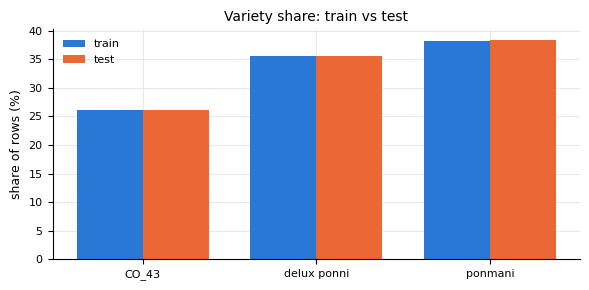

Variety share (%):
 Variety  CO_43  delux ponni  ponmani
all       26.1         35.6     38.3
train     26.2         35.6     38.3
test      26.1         35.6     38.3

Hectares share (%):
 Hectares   1    2    3    4    5   6
train    8.6 14.3 16.8 23.6 28.6 8.1
test       9 17.5   13 20.9 31.1 8.5

Agriblock share (%):
 Agriblock  Chinnasalem  Cuddalore  Kallakurichi  Kurinjipadi  Panruti  Sankarapuram
train             15.5       16.1          14.7         17.5     15.2          20.9
test              14.8       14.2          16.1         16.2     15.8          22.8


In [45]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(df, test_size=0.30, random_state=SEED, stratify=df[TARGET])
print('train', train.shape, '| test', test.shape)

share = lambda d, c: d[c].value_counts(normalize=True).mul(100)
cls = pd.concat([share(df, TARGET).rename('all'), share(train, TARGET).rename('train'), share(test, TARGET).rename('test')], axis=1).loc[CLASSES]

fig, ax = plt.subplots(figsize=(6, 3))
x = np.arange(len(CLASSES)); w = 0.38
ax.bar(x - w/2, cls['train'], w, color=BLUE, label='train')
ax.bar(x + w/2, cls['test'], w, color=ORANGE, label='test')
ax.set(xticks=x, xticklabels=CLASSES, ylabel='share of rows (%)', title='Variety share: train vs test'); ax.legend()
plt.tight_layout(); plt.show()

print('Variety share (%):\n', cls.round(1).T.to_string())
for c in ['Hectares', 'Agriblock']:
    print(f'\n{c} share (%):\n', pd.concat([share(train, c).sort_index().rename('train'), share(test, c).sort_index().rename('test')], axis=1).round(1).T.to_string())

In [46]:
# ---- Amount of leakage if duplicates were kept (same seed, split before removing duplicates) ----
rs_tr, rs_te = train_test_split(raw, test_size=0.30, random_state=SEED, stratify=raw[TARGET])
hit = rs_te.merge(rs_tr.drop_duplicates(), how='left', indicator=True)['_merge'].eq('both').mean()
print(f'If duplicates were kept, {hit:.1%} of TEST rows would have an exact copy (all 45 columns) in TRAIN.')

tw = test[FEATURES].merge(train[FEATURES].drop_duplicates(), how='left', indicator=True)['_merge'].eq('both').mean()
print(f'After de-duplication, {tw:.1%} of test rows share their whole 44-feature vector with a training row.')

If duplicates were kept, 22.1% of TEST rows would have an exact copy (all 45 columns) in TRAIN.
After de-duplication, 0.0% of test rows share their whole 44-feature vector with a training row.


**Reading:**
* The split is representative: `Variety` shares are equal by construction (CO_43 26 %, delux ponni 36 %, ponmani 38 %), and `Hectares` / `Agriblock` shares are close
* Keeping duplicates would have let **22.1 %** of test rows be answered from memory.
* After de-duplication, **0 %** of test feature vectors have a twin in train, so every test row is genuinely unseen.

# 4 · Target distribution
**Checks (Guideline):** balance, skewness, outliers. `Variety` is **nominal**, so only balance applies:
* **Skewness** needs an ordered numeric scale; class labels have no order, so it is undefined.
* **Outliers** are extreme values on a numeric scale; a label is either one of the 3 valid classes or not, which was already checked in the quality audit (all labels valid).

,count,share (%)
Variety,,
CO_43,428,26.1614
delux ponni,582,35.5746
ponmani,626,38.2641


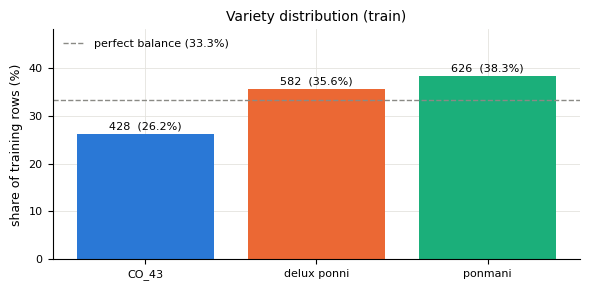

imbalance ratio (largest / smallest class): 1.46


In [47]:
tr = train.copy()                                    # <- all EDA and feature-selection cells from here on use `tr` (train only)

cnt = tr[TARGET].value_counts().reindex(CLASSES)
tgt = pd.DataFrame({'count': cnt, 'share (%)': cnt / cnt.sum() * 100})
display(tgt)

fig, ax = plt.subplots(figsize=(6, 3))
bars = ax.bar(CLASSES, tgt['share (%)'], color=[BLUE, ORANGE, AQUA])
ax.bar_label(bars, labels=[f'{n}  ({p:.1f}%)' for n, p in zip(tgt['count'], tgt['share (%)'])], fontsize=8, padding=2)
ax.axhline(100 / len(CLASSES), color=GREY, ls='--', lw=1, label='perfect balance (33.3%)')
ax.set(ylabel='share of training rows (%)', title='Variety distribution (train)', ylim=(0, 48)); ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

p = cnt / cnt.sum()
print(f'imbalance ratio (largest / smallest class): {cnt.max() / cnt.min():.2f}')

In [48]:
# ---- One-vs-Rest view: each binary sub-problem's positive share ----
ovr = pd.DataFrame({'positive (this variety)': cnt, 'negative (other two)': cnt.sum() - cnt})
ovr['positive share (%)'] = ovr.iloc[:, 0] / cnt.sum() * 100
ovr['neg / pos ratio'] = ovr.iloc[:, 1] / ovr.iloc[:, 0]
ovr.index = [f'{c} vs rest' for c in CLASSES]
ovr

,positive (this variety),negative (other two),positive share (%),neg / pos ratio
CO_43 vs rest,428,1208,26.1614,2.8224
delux ponni vs rest,582,1054,35.5746,1.811
ponmani vs rest,626,1010,38.2641,1.6134


### 4.1 Reading — target distribution
* **Balance:** 428 / 582 / 626 (CO_43 / delux ponni / ponmani) of 1,636 training rows. The largest/smallest ratio is 1.46, so the classes are **mildly imbalanced**: `CO_43` is the minority (26.2 %), the other two are close to each other.
* **One-vs-Rest:** splitting into 3 binary problems makes each one more imbalanced than the 3-class problem. `CO_43 vs rest` is the hardest at 2.8 negatives per positive.

**Discussion**
* No resampling: a ratio of 1.46 is mild
* The 70/30 split already keeps these proportions in train and test.

# 5 · Initial feature exploration
**Purpose:** gauge volume and type of data, then drop any column that clearly does not affect the target.

**Tools:** 
- unique-value count
- share of the most frequent value
- the low-variance rule (drop zero-variance columns)

**Assumption:** a column that (almost) never changes carries no information for *any* model, regardless of target.

In [49]:
from sklearn.feature_selection import VarianceThreshold

ov = pd.DataFrame({'dtype': tr[FEATURES].dtypes.astype(str), 'n_unique': tr[FEATURES].nunique(),
                   'missing': tr[FEATURES].isna().sum(),
                   'top value share %': [tr[c].value_counts(normalize=True).iloc[0] * 100 for c in FEATURES]})
ov['role'] = ['categorical' if c in CAT else 'numeric' for c in ov.index]
display(ov.sort_values(['role', 'n_unique']))
const = ov[ov.n_unique == 1].index.tolist()
vt = VarianceThreshold(0.0).fit(tr[NUM]); zero_var = [c for c, k in zip(NUM, vt.get_support()) if not k]
print('constant columns (n_unique==1):', const, '| zero-variance numeric (VarianceThreshold(0)):', zero_var)

,dtype,n_unique,missing,top value share %,role
Soil Types,object,2,0,54.0342,categorical
Nursery,object,2,0,53.8509,categorical
Wind Direction_D31_D60,object,5,0,37.0416,categorical
Wind Direction_D61_D90,object,5,0,32.2127,categorical
Agriblock,object,6,0,20.9046,categorical
Wind Direction_D1_D30,object,6,0,20.9046,categorical
Wind Direction_D91_D120,object,6,0,20.9046,categorical
30DRain( in mm),float64,3,0,36.4303,numeric
30_50DRain( in mm),float64,3,0,36.4303,numeric
51_70DRain(in mm),float64,3,0,36.4303,numeric


constant columns (n_unique==1): [] | zero-variance numeric (VarianceThreshold(0)): []


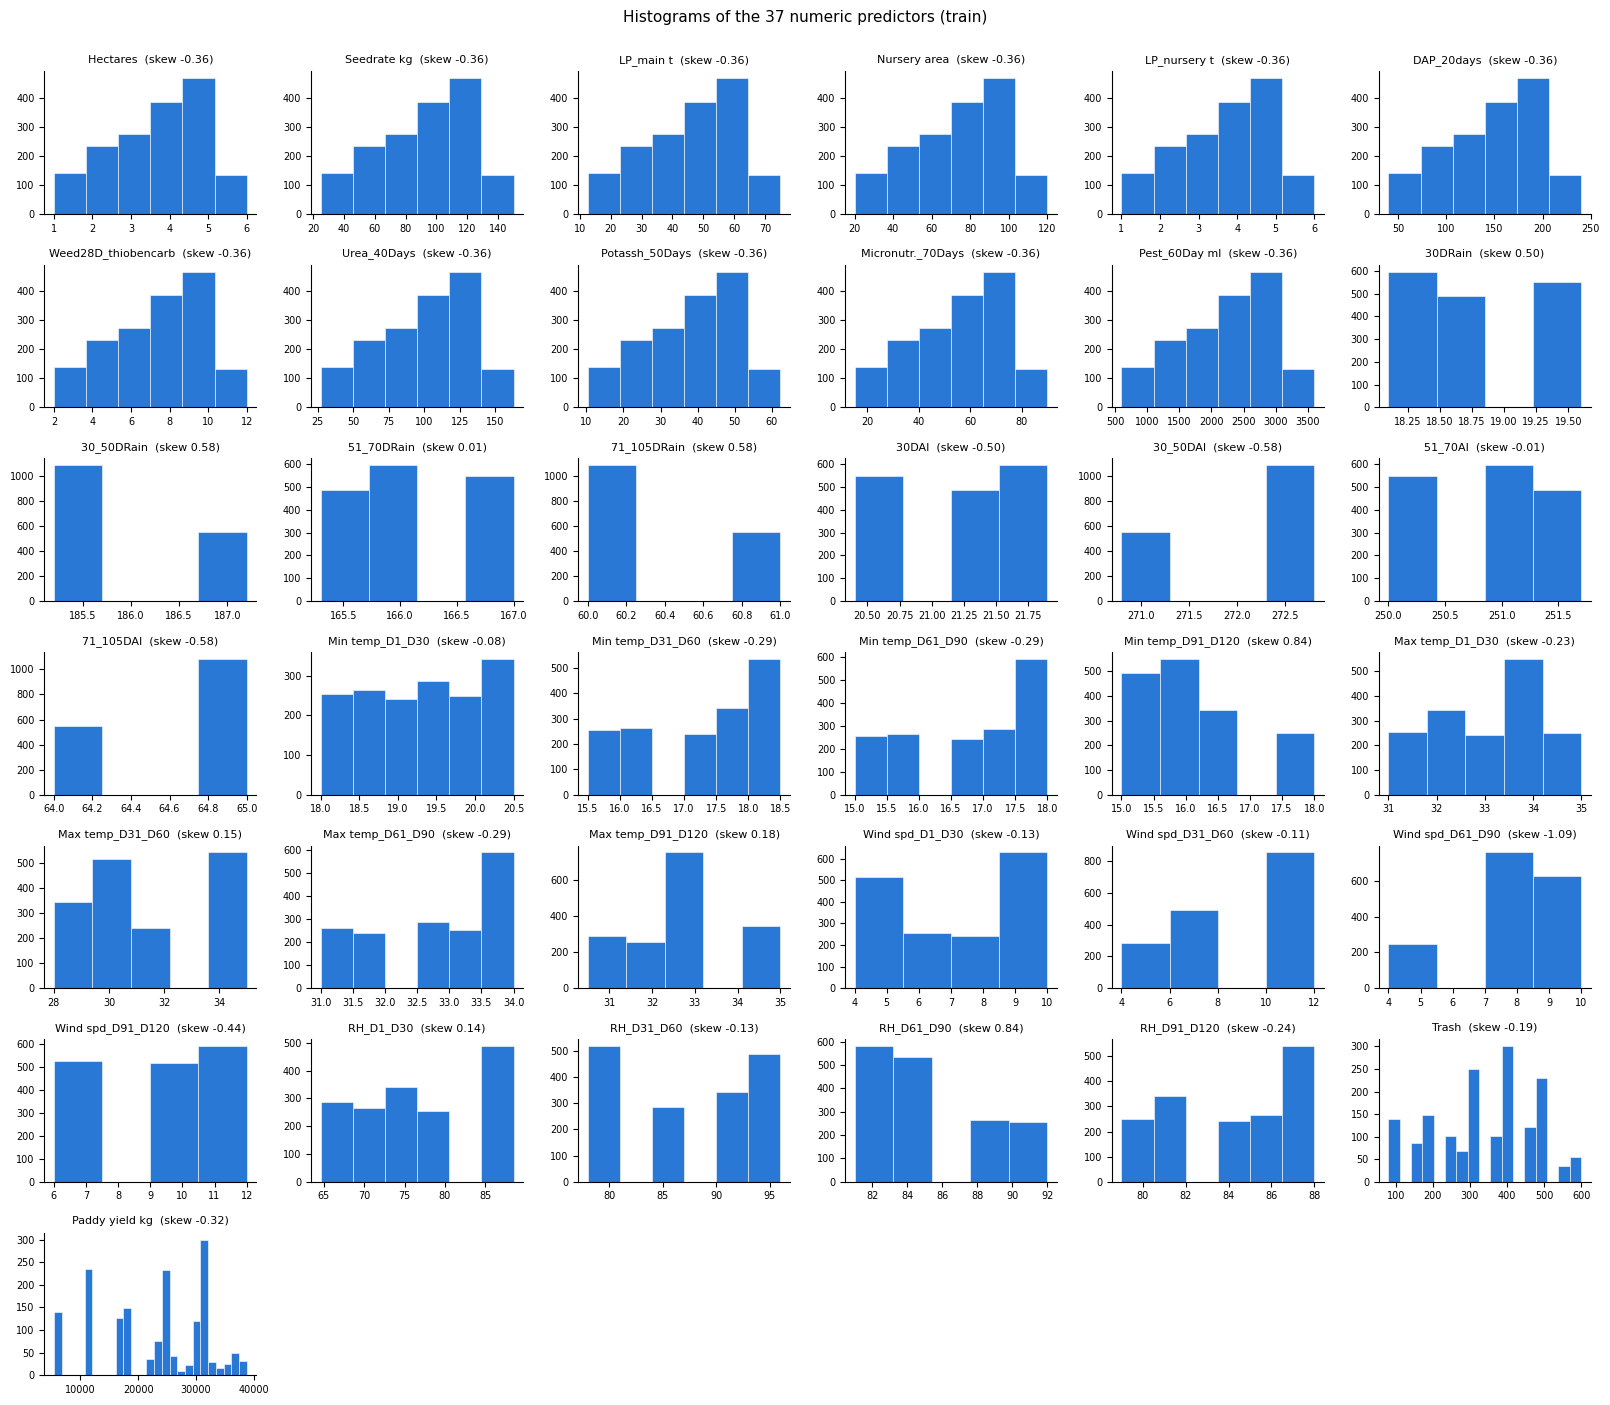

In [50]:
# ---- Visual histogram for continuous / bar chart for categorical ----
def short(c):
    for a, b in [('Inst Wind Speed', 'Wind spd'), ('Relative Humidity', 'RH'), ('(in Knots)', ''), ('(in Tonnes)', ' t'), ('(in Kg)', ' kg'),
                 ('(in ml)', ' ml'), ('( in mm)', ''), ('(in mm)', ''), ('(in bundles)', ''), ('Wind Direction', 'Wind dir'), ('Micronutrients', 'Micronutr.'),
                 ('LP_nurseryarea', 'LP_nursery'), ('LP_Mainfield', 'LP_main'), ('Nursery area (Cents)', 'Nursery area')]: c = c.replace(a, b)
    return c.strip()

def grid(n, ncols, w, h):
    nr = int(np.ceil(n / ncols)); fig, ax = plt.subplots(nr, ncols, figsize=(ncols*w, nr*h)); ax = np.atleast_1d(ax).ravel()
    for a in ax[n:]: a.axis('off')
    return fig, ax

fig, ax = grid(len(NUM), 6, 2.7, 2.0)
for a, c in zip(ax, NUM):
    a.hist(tr[c], bins=min(25, max(4, tr[c].nunique())), color=BLUE, edgecolor='white', lw=0.4); a.set_title(f'{short(c)}  (skew {tr[c].skew():.2f})', fontsize=8); a.tick_params(labelsize=7); a.grid(False)
plt.suptitle(f'Histograms of the {len(NUM)} numeric predictors (train)', y=1.0, fontsize=11); plt.tight_layout(); plt.show()

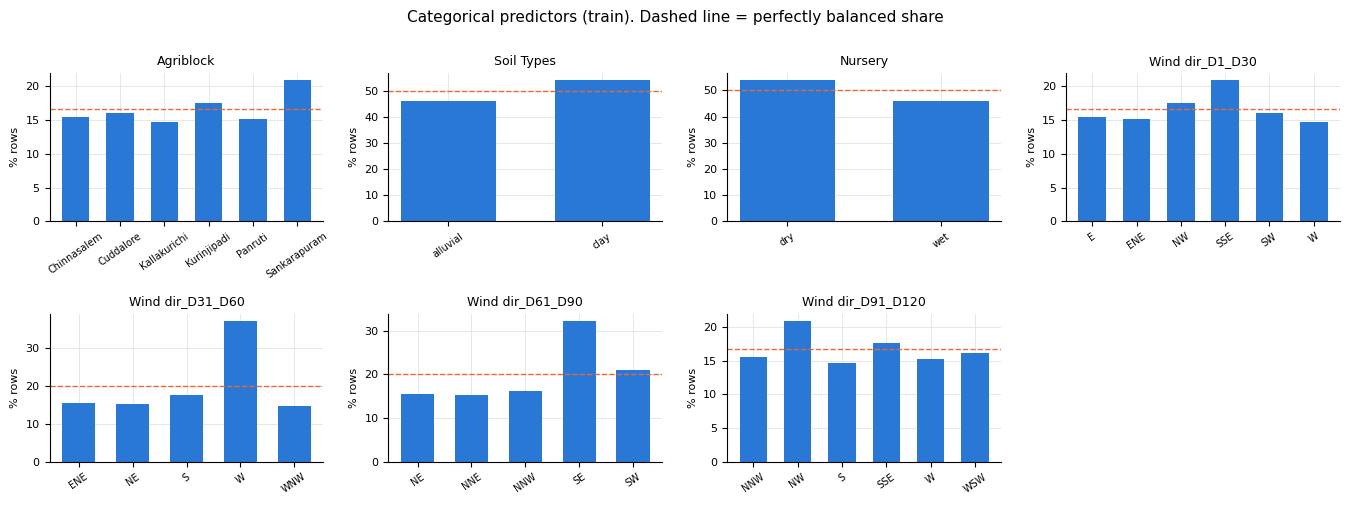

,levels,min_share,max_share,max/min
Agriblock,6,14.6699,20.9046,1.425
Soil Types,2,45.9658,54.0342,1.1755
Nursery,2,46.1491,53.8509,1.1669
Wind Direction_D1_D30,6,14.6699,20.9046,1.425
Wind Direction_D31_D60,5,14.6699,37.0416,2.525
Wind Direction_D61_D90,5,15.22,32.2127,2.1165
Wind Direction_D91_D120,6,14.6699,20.9046,1.425


|skewness| > 1 : {'Inst Wind Speed_D61_D90(in Knots)': -1.09}
|skewness| > 0.5: 7 of 37 numeric features


In [51]:
fig, ax = grid(len(CAT), 4, 3.4, 2.5)
for a, c in zip(ax, CAT):
    vc = tr[c].value_counts(normalize=True).sort_index() * 100
    a.bar(vc.index, vc.values, color=BLUE, width=0.62); a.set_title(short(c), fontsize=9); a.set_ylabel('% rows', fontsize=8); a.tick_params(axis='x', rotation=35, labelsize=7); a.axhline(100/len(vc), color=ORANGE, lw=1, ls='--')
plt.suptitle('Categorical predictors (train). Dashed line = perfectly balanced share', y=1.0, fontsize=11); plt.tight_layout(); plt.show()
bal = pd.DataFrame({c: dict(levels=tr[c].nunique(), min_share=tr[c].value_counts(normalize=True).min()*100, max_share=tr[c].value_counts(normalize=True).max()*100) for c in CAT}).T
bal['max/min'] = bal.max_share / bal.min_share
display(bal)
sk = tr[NUM].skew().sort_values(); print('|skewness| > 1 :', sk[sk.abs() > 1].round(2).to_dict()); print('|skewness| > 0.5:', len(sk[sk.abs() > 0.5]), 'of', len(sk), 'numeric features')

### 5.1 Discussion — feature exploration
**Column dropping:**
* No column is constant, and no column has one value covering over 80% of rows. So **no column is dropped by the low-variance rule**.
* No column is an identifier, so none is dropped as clearly unrelated to the target.

**What the histograms show:**
* Almost every numeric column takes only **3-6 distinct values**; only `Trash` (17) and `Paddy yield` (393) vary more.
* **11 columns (`Hectares` + the 10 input columns: `Seedrate`, `LP_Mainfield`, `Nursery area`, `LP_nurseryarea`, `DAP_20days`, `Weed28D_thiobencarb`, `Urea_40Days`, `Potassh_50Days`, `Micronutrients_70Days`, `Pest_60Day`) have identical histograms and identical skewness (-0.36)**: they look like the same variable on different scales.
* The 4 rain and 4 AI columns are **mirror images** of each other (skewness +0.50 vs -0.50, +0.58 vs -0.58, +0.01 vs -0.01).
* Skewness: only `Wind spd_D61_D90` has |skew| > 1 (-1.09); 7 of 37 have |skew| > 0.5. Decision: **don't transform predictors**. most columns have too few levels for log/Box-Cox to reshape them, and logistic regression does not assume normally distributed predictors.

**Categorical balance:**
* `Agriblock`, `Soil Types` and `Nursery` are close to the dashed line (max/min share at most 1.43).
* `Wind dir_D31_D60` (W = 37.0%) and `Wind dir_D61_D90` (SE = 32.2%) are the least even, but no level is rare (smallest share 14.7%), so all levels are kept as they are.
* `Wind Direction_D1_D30` and `_D91_D120` have exactly the same share pattern as `Agriblock` (14.7-20.9%): wind direction appears to follow the agri-block (location).

# 6 · Outlier analysis
**Why it matters:** "No High Leverage Points or Influential Outliers" is one of the data assumptions for logistic regression. Logistic regression scores a row with the linear score $\mathbf{w}_k^\top\mathbf{x}+b_k$, so one extreme value of $\mathbf{x}$ moves the score a lot and can pull the decision boundary towards itself. Causes: data-entry errors, sensor faults, or genuinely rare events.

**Detection tools used and their assumptions**

| Tool | Rule | Assumption / weakness |
|---|---|---|
| Visual (histogram / box-plot) | look for isolated points | judgement-based; box-plot fliers (beyond 1.5 × IQR) are unreliable on columns with only a few levels |
| **z-score** (2-3 SD from mean) | \|z\| > 3, with \|z\| > 2 also reported | data must be roughly **Gaussian** |
| **z-score within each class** | \|z\| > 3 using each variety's own mean and SD | same as above; finds a value that is normal overall but extreme *for its variety*, which is what can mislead a classifier |


columns with at least one flag:


,n_unique,global |z|>3,global |z|>2,within-class |z|>3
Min temp_D91_D120,5,0,249,0
Inst Wind Speed_D61_D90(in Knots),3,0,249,0


flags in total over 37 columns x 1636 rows -> global |z|>3: 0 | within-class |z|>3: 0


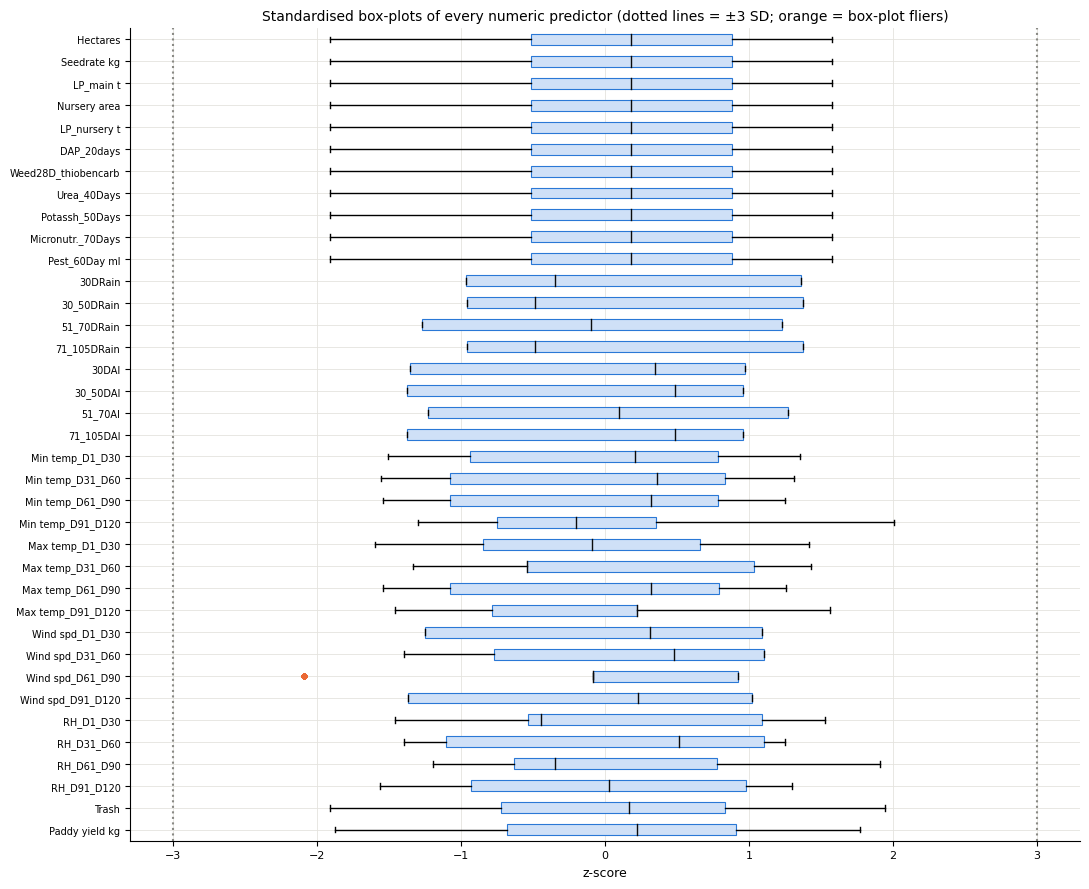

In [52]:
z  = (tr[NUM] - tr[NUM].mean()) / tr[NUM].std(ddof=0)                                   # global z-score
zc = tr.groupby(TARGET)[NUM].transform(lambda s: (s - s.mean()) / s.std(ddof=0))          # z-score within each variety
out = pd.DataFrame({'n_unique': tr[NUM].nunique(), 'global |z|>3': (z.abs() > 3).sum(), 'global |z|>2': (z.abs() > 2).sum(),
                    'within-class |z|>3': (zc.abs() > 3).sum()})
print('columns with at least one flag:'); display(out[out.drop(columns='n_unique').sum(axis=1) > 0])
print(f"flags in total over {len(NUM)} columns x {len(tr)} rows -> global |z|>3: {int(out['global |z|>3'].sum())} | within-class |z|>3: {int(out['within-class |z|>3'].sum())}")

fig, ax = plt.subplots(figsize=(11, 9))
ax.boxplot([z[c] for c in NUM], vert=False, patch_artist=True, boxprops=dict(facecolor='#cfe0f7', color=BLUE, lw=0.8), medianprops=dict(color=INK), flierprops=dict(marker='o', ms=3, mfc=ORANGE, mec=ORANGE))
ax.set_yticklabels([short(c) for c in NUM], fontsize=7); ax.axvline(-3, color=GREY, ls=':'); ax.axvline(3, color=GREY, ls=':'); ax.invert_yaxis()
ax.set(title='Standardised box-plots of every numeric predictor (dotted lines = ±3 SD; orange = box-plot fliers)', xlabel='z-score'); plt.tight_layout(); plt.show()

In [53]:
# ---- What the |z|>2 flags actually are: a whole level of a few-level column, not isolated points ----
for c in out[out['global |z|>2'] > 0].index:
    vc = tr[c].value_counts().sort_index()
    print(f'{short(c)}: levels {vc.to_dict()}  -> flagged level(s): {sorted(tr.loc[z[c].abs() > 2, c].unique().tolist())}')

Min temp_D91_D120: levels {15.0: 254, 15.5: 240, 16.0: 551, 16.5: 342, 18.0: 249}  -> flagged level(s): [18.0]
Wind spd_D61_D90: levels {4: 249, 8: 758, 10: 629}  -> flagged level(s): [4]


### 6.1 Discussion — outliers
**Statistics (z-score):**
* Global: 0 values with |z| > 3
* Within each variety: 0 values with |z| > 3, so no plot is extreme for its own variety either.
* there are |z| > 2 but each time it is **one whole level**, not isolated points: `Min temp_D91_D120` = 18.0 and `Wind spd_D61_D90` = 4 knots (15.2% of rows each).

**Plots (box-plot):**
* Every whisker sits within ±3 SD.
* The single orange flier on `Wind spd_D61_D90` is the 4-knot level (3 levels: 4 / 8 / 10, with 46% of rows at 8). The quartiles squeeze together, so the lowest level looks like it's outside the box. This comes from using a box-plot on a column with few levels, not from a data error.

**Decision: no rows removed, no values capped.**
1. No sign of a measurement error: every flagged value is a level shared by about 15% of rows and is plausible weather.
2. Removing a whole level would delete real weather records and shrink the training set, with nothing gained.

# 7 · Missing-value analysis
handle each column separately
- missing > 30% --> drop the column 
- a few missing rows --> drop those rows
- otherwise **impute** (mean / median / mode / others)

Two kinds of missing are checked: 
- **explicit** (empty cells, `NaN`) 
- **disguised** (a placeholder such as `?`, `-`, `NA`, `unknown`, or a `0` where zero is physically impossible, e.g. plot size or temperature).

In [54]:
miss = pd.DataFrame({'missing_n': tr.isna().sum(), 'missing_%': tr.isna().mean() * 100})
print('explicit: columns with any missing value:', int((miss.missing_n > 0).sum()), '| maximum missing % in any column:', miss['missing_%'].max())
print('explicit: rows with a missing Variety label:', int(tr[TARGET].isna().sum()))

PLACEHOLDERS = {'?', '-', '', 'na', 'n/a', 'nan', 'none', 'null', 'unknown'}
ph = {c: int(tr[c].astype(str).str.strip().str.lower().isin(PLACEHOLDERS).sum()) for c in CAT + [TARGET]}
print('disguised: placeholder strings in text columns:', sum(ph.values()))
zeros = (tr[NUM] == 0).sum()
print('disguised: zeros in numeric columns:', int(zeros.sum()), '| columns:', zeros[zeros > 0].to_dict() if zeros.sum() else 'none')

print('test part (only counts, nothing learned from it): explicit', int(test.isna().sum().sum()),
      '| zeros', int((test[NUM] == 0).sum().sum()))

explicit: columns with any missing value: 0 | maximum missing % in any column: 0.0
explicit: rows with a missing Variety label: 0
disguised: placeholder strings in text columns: 0
disguised: zeros in numeric columns: 0 | columns: none
test part (only counts, nothing learned from it): explicit 0 | zeros 0


**Result: nothing is missing** 

# 8 · Feature selection — continuous features
**Goal:** keep numeric columns related to `Variety`, using **filter methods**. Everything is computed on `train` only.

### 8.1 Visual analysis
Each panel: one numeric predictor; dot = its **mean in each variety**, bar = ±1 SD inside that variety. Dots far apart with short bars = the feature separates the varieties (between-class variance high, within-class variance low).

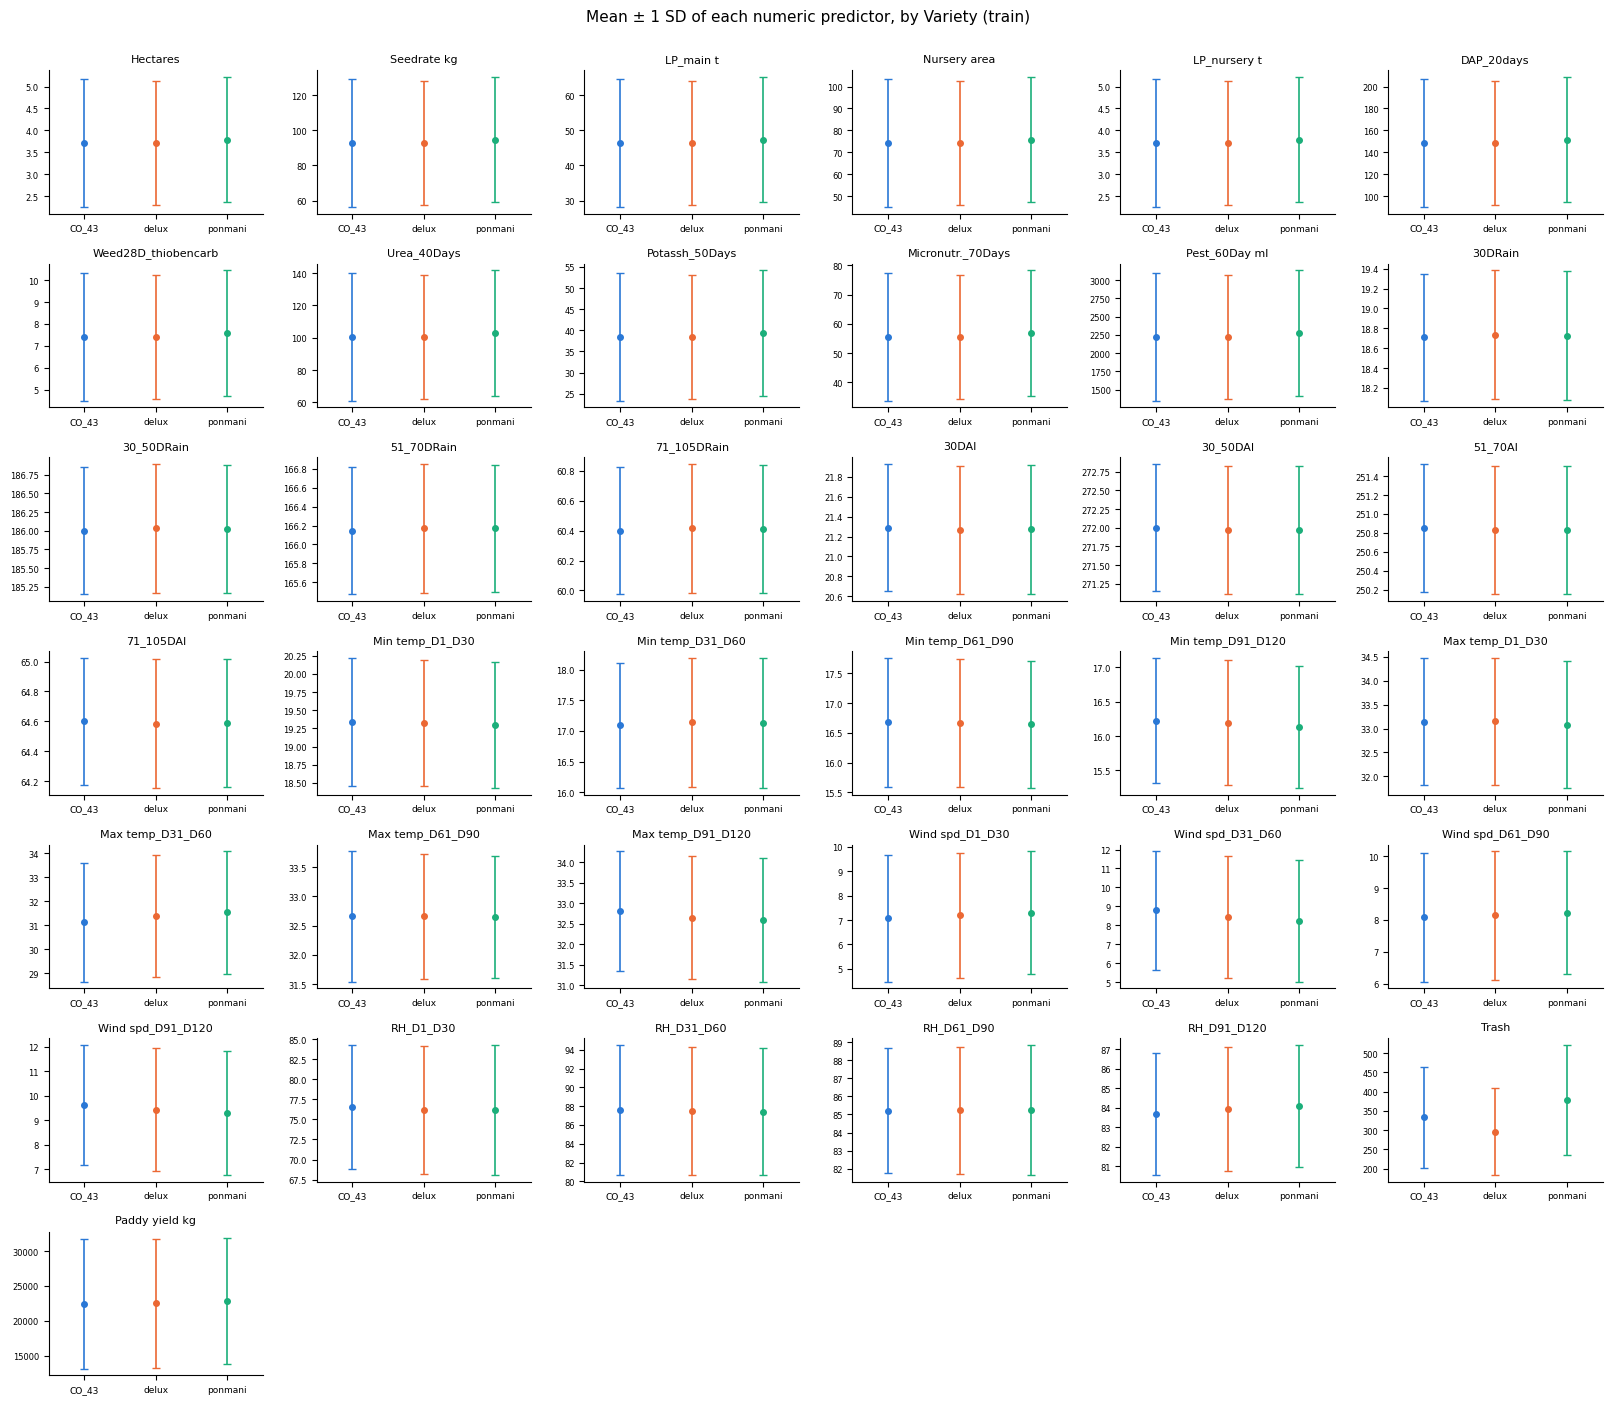

In [55]:
fig, ax = grid(len(NUM), 6, 2.7, 2.0)
cols3 = [BLUE, ORANGE, AQUA]
for a, c in zip(ax, NUM):
    m = tr.groupby(TARGET)[c].mean().reindex(CLASSES); s = tr.groupby(TARGET)[c].std().reindex(CLASSES)
    for i, k in enumerate(CLASSES): a.errorbar(i, m[k], yerr=s[k], fmt='o', color=cols3[i], ms=4, capsize=3, lw=1.2)
    a.set_xticks(range(3)); a.set_xticklabels(['CO_43', 'delux', 'ponmani'], fontsize=6.5); a.set_xlim(-0.5, 2.5)
    a.set_title(short(c), fontsize=8); a.tick_params(axis='y', labelsize=6); a.grid(False)
plt.suptitle('Mean ± 1 SD of each numeric predictor, by Variety (train)', y=1.0, fontsize=11); plt.tight_layout(); plt.show()

`Trash` is the only panel where the variety means differ, but its bars overlap a lot. `Trash` is a total per plot, so bigger plots should have more of it, and plot sizes range from 1 to 6 ha. The overlap may therefore come from plot size. Plotting `Trash against Hectares`, coloured by variety, checks whether the varieties separate once plot size is taken into account.

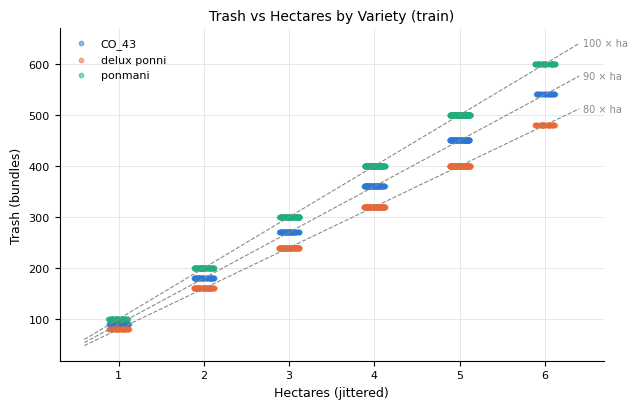

Trash per hectare by Variety (num of rows train):
Variety       CO_43  delux ponni  ponmani
Trash per ha                             
80                0          582        0
90              428            0        0
100               0            0      626


In [56]:
# ---- Two features together: Trash vs Hectares, coloured by Variety ----
rng = np.random.default_rng(SEED)
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for k, col in zip(CLASSES, cols3):
    d = tr[tr[TARGET] == k]
    ax.scatter(d['Hectares'] + rng.uniform(-0.12, 0.12, len(d)), d[TRASH], s=10, alpha=0.5, color=col, label=k)
ha = np.array([0.6, 6.4])
for r in (80, 90, 100): ax.plot(ha, r * ha, color=GREY, lw=0.8, ls='--'); ax.text(6.45, r * 6.4, f'{r} × ha', fontsize=7, va='center', color=GREY)
ax.set(xlabel='Hectares (jittered)', ylabel='Trash (bundles)', title='Trash vs Hectares by Variety (train)'); ax.legend(loc='upper left')
plt.tight_layout(); plt.show()
print('Trash per hectare by Variety (num of rows train):'); print(pd.crosstab((tr[TRASH] / tr['Hectares']).rename('Trash per ha'), tr[TARGET]))

**Reading the plots**
* **`Trash`** is the only panel where the variety means clearly differ, but the ±1 SD bars still overlap a lot because Trash also grows with plot size.
* **Every other panel:** the 3 dots sit at almost the same height with long, overlapping bars.
* **Trash vs Hectares:** each variety lies on its own straight line, Trash = **80** (delux ponni), **90** (CO_43) or **100** (ponmani) × Hectares, with no overlap in train. So `Hectares` alone says nothing about variety, but **`Hectares` and `Trash` together separate the 3 varieties**.

### 8.2 Statistical analysis
| Tool | Measures | Assumptions / limits |
|---|---|---|
| **ANOVA F-test** (`f_classif`; H0: the feature's mean is equal in all 3 varieties) | F = variance *between* varieties / variance *within* varieties; significant if p < 0.05 | normality within each class, roughly equal variance in each class, independent rows; sees only differences in the **mean** |
| **Mutual information** (`mutual_info_classif`, nats) | *any* kind of dependency, ≥ 0, no p-value | used as a **ranking**, not a thresholded test; columns with ≤ 20 levels are marked as discrete |

**Rule:** a feature is a candidate if its ANOVA p < 0.05; MI is used to rank features. Both look at **one feature at a time**.

In [57]:
from sklearn.feature_selection import f_classif, mutual_info_classif

F, p = f_classif(tr[NUM], tr[TARGET])
mi = mutual_info_classif(tr[NUM], tr[TARGET], discrete_features=(tr[NUM].nunique() <= 20).values, random_state=SEED)
sd = tr.groupby(TARGET)[NUM].std()
ct_tab = pd.DataFrame({'F': F, 'p': p, 'MI': mi, 'class SD max/min': sd.max() / sd.min()}, index=NUM)
ct_tab['p < 0.05'] = ct_tab.p < 0.05
ct_tab = ct_tab.sort_values('F', ascending=False)
ct_tab.index = [short(c) for c in ct_tab.index]
display(ct_tab)
print('features with p < 0.05:', ct_tab.index[ct_tab['p < 0.05']].tolist())
print(f'expected number passing by chance alone if no feature were related: 0.05 x {len(NUM)} = {0.05 * len(NUM):.1f}')

,F,p,MI,class SD max/min,p < 0.05
Trash,60.6779,3.81e-26,0.9589,1.2616,True
Wind spd_D31_D60,3.6218,0.027,0.0027,1.0275,True
Max temp_D31_D60,3.4728,0.0313,0.0028,1.0364,True
Max temp_D91_D120,2.7448,0.0646,0.0028,1.0309,False
Wind spd_D91_D120,2.4299,0.0884,0.0015,1.0338,False
RH_D91_D120,2.1139,0.1211,0.0029,1.0129,False
Min temp_D91_D120,1.4201,0.242,0.0012,1.0282,False
Wind spd_D1_D30,1.1325,0.3225,0.0015,1.0299,False
Wind spd_D61_D90,0.7273,0.4834,0.0005,1.0453,False
Seedrate kg,0.6521,0.5211,0.001,1.0279,False


features with p < 0.05: ['Trash', 'Wind spd_D31_D60', 'Max temp_D31_D60']
expected number passing by chance alone if no feature were related: 0.05 x 37 = 1.9


### 8.3 Discussion — continuous feature selection
**Rule result:** 3 features have p < 0.05: `Trash`, `Wind spd_D31_D60`, `Max temp_D31_D60`.

| | Features | ANOVA | MI (nats) | Reading | Decision |
|---|---|---|---|---|---|
| **(a)** | `Trash` | F = 60.7, p = 3.8e-26 | 0.96 (largest) | Class SDs within 1.26× of each other (roughly equal variance). Values are not normal (17 levels), but each class has 428-626 rows, so the F-test is not sensitive to this | **keep** |
| **(b)** | `Wind spd_D31_D60`, `Max temp_D31_D60` | p = 0.027, p = 0.031 | ≈ 0.003 | Pass the rule, but the effect is tiny: the mean shift is well inside one SD in the plot | **keep as candidates**, flagged as weak |
| **(c)** | `Hectares` + 10 input columns: `Seedrate`, `LP_Mainfield`, `Nursery area`, `LP_nurseryarea`, `DAP_20days`, `Weed28D_thiobencarb`, `Urea_40Days`, `Potassh_50Days`, `Micronutrients_70Days`, `Pest_60Day` | F = 0.65, p = 0.52 (all 11; each is an exact multiple of `Hectares`) | 0.001 | Fail the rule, but the Trash-vs-Hectares plot shows `Hectares` is needed *together with* `Trash`: the variety is set by Trash **per hectare**, and a linear model needs both columns to draw boundaries such as Trash = 85 × Hectares and Trash = 95 × Hectares. Filter methods test **one feature at a time**, so they miss a feature that is only useful in combination | **keep `Hectares`** despite p = 0.52; the 10 input columns carry the same information, kept as candidates for now |
| **(d)** | other 22 weather columns, `Paddy yield` | p = 0.065-0.99 | ≤ 0.003 (`Paddy yield` 0.020) | No difference between varieties | **reject** |

**Summary:** keep **14** (`Trash`, `Hectares`, the 10 input columns in (c), `Wind spd_D31_D60`, `Max temp_D31_D60`); reject **23**.

# 9 · Feature selection — categorical features
**Goal:** keep the categorical columns related to `Variety`, using filter methods on `train` only. Feature and target are **both categorical** here, so the chi-square test applies directly.

### 9.1 Visual analysis
Each panel: one categorical predictor; each bar = one of its levels, split by the **share of each variety** in that level. Dashed lines = the overall variety shares in train. If every bar matches the dashed lines, the feature tells nothing about the variety.

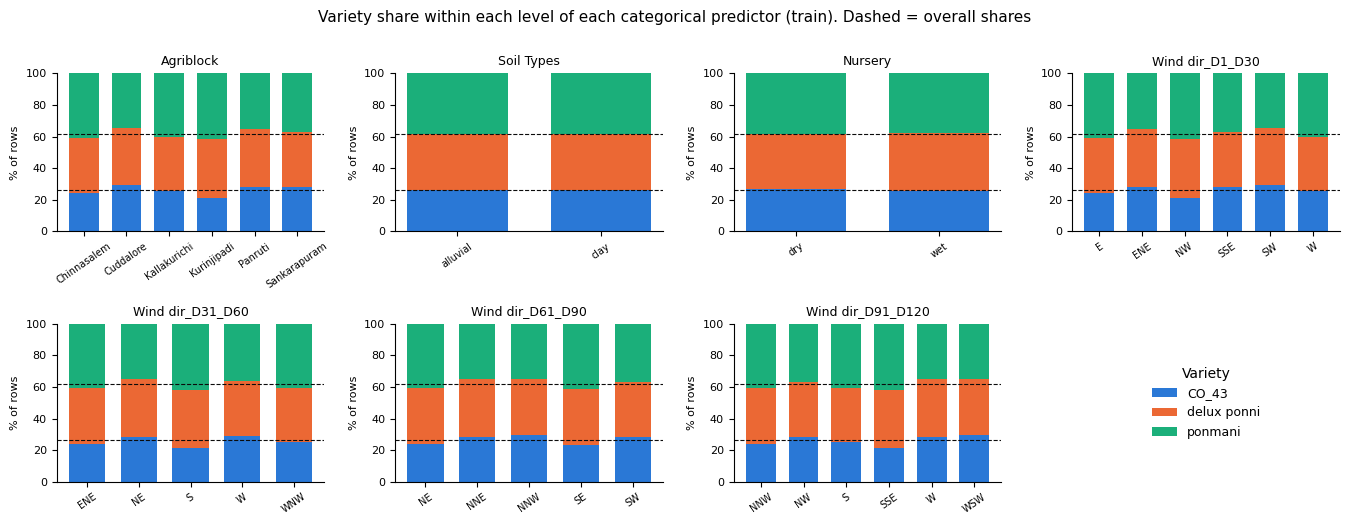

In [58]:
overall = tr[TARGET].value_counts(normalize=True).reindex(CLASSES).cumsum().values[:-1] * 100
fig, ax = grid(len(CAT), 4, 3.4, 2.6)
for a, c in zip(ax, CAT):
    sh = pd.crosstab(tr[c], tr[TARGET], normalize='index').reindex(columns=CLASSES) * 100
    bottom = np.zeros(len(sh))
    for k, col in zip(CLASSES, cols3):
        a.bar(sh.index, sh[k], bottom=bottom, color=col, width=0.7, label=k); bottom += sh[k].values
    for y in overall: a.axhline(y, color=INK, lw=0.8, ls='--')
    a.set_title(short(c), fontsize=9); a.set_ylim(0, 100); a.set_ylabel('% of rows', fontsize=8); a.tick_params(axis='x', rotation=35, labelsize=7); a.grid(False)
ax[len(CAT)].legend(*ax[0].get_legend_handles_labels(), loc='center', fontsize=9, title='Variety')   # legend in the empty panel
plt.suptitle('Variety share within each level of each categorical predictor (train). Dashed = overall shares', y=1.0, fontsize=11); plt.tight_layout(); plt.show()

**Reading the plot:** in every panel the bars are close to the dashed lines. No level is dominated by one variety.

### 9.2 Statistical analysis
| Tool | Tests | Assumptions / limits |
|---|---|---|
| **Chi-square test of independence** (`chi2_contingency` on the level × variety contingency table; H0: feature and `Variety` are independent) | whether the observed counts differ from the counts expected if the two were unrelated; significant if p < 0.05 | independent rows; expected count in every cell not too small (≥ 5 is the usual rule of thumb; minimum printed as `min_expected`) |
| **Mutual information** (`mutual_info_classif`, nats) | any kind of dependency | ranking only, no p-value |

**Rule:** keep a categorical column if its chi-square p < 0.05; MI is used to rank.

In [59]:
cat_rows = {}
for c in CAT:
    ctab = pd.crosstab(tr[c], tr[TARGET])
    chi2, pc, _, exp = stats.chi2_contingency(ctab)
    mi = mutual_info_classif(pd.factorize(tr[c])[0].reshape(-1, 1), tr[TARGET], discrete_features=True, random_state=SEED)[0]
    cat_rows[short(c)] = dict(levels=tr[c].nunique(), chi2=chi2, p=pc, min_expected=exp.min(), MI=mi,
                              levels_per_Agriblock=(pd.crosstab(tr['Agriblock'], tr[c]) > 0).sum(axis=1).max())
cat_tab = pd.DataFrame(cat_rows).T
cat_tab['p < 0.05'] = cat_tab.p < 0.05
display(cat_tab)

,levels,chi2,p,min_expected,MI,levels_per_Agriblock,p < 0.05
Agriblock,6,9.201,0.5131,62.7873,0.0029,1,False
Soil Types,2,0.0058,0.9971,196.7335,1.78e-06,2,False
Nursery,2,1.0657,0.5869,197.5183,0.0003,2,False
Wind dir_D1_D30,6,9.201,0.5131,62.7873,0.0029,1,False
Wind dir_D31_D60,5,8.939,0.3475,62.7873,0.0028,1,False
Wind dir_D61_D90,5,7.9876,0.4347,65.1418,0.0024,1,False
Wind dir_D91_D120,6,9.201,0.5131,62.7873,0.0029,1,False


### 9.3 Discussion — categorical feature selection
**Rule result:** no categorical column has chi-square p < 0.05. The smallest expected count in any table is 62.8 (well above 5), so the chi-square results are valid.

| | Features | Chi-square | MI (nats) | Reading | Decision |
|---|---|---|---|---|---|
| **(a)** | `Agriblock` | χ² = 9.20, p = 0.51 | 0.003 | Every block grows all 3 varieties in similar shares | **reject** |
| **(b)** | `Soil Types`, `Nursery` | p = 0.997, 0.59 | ≤ 0.0003 | Variety shares are the same on both soils and with both nursery methods | **reject** |
| **(c)** | `Wind Direction_D1_D30`, `_D31_D60`, `_D61_D90`, `_D91_D120` | p = 0.35-0.51 | ≤ 0.003 | Each column has exactly **one direction per agri-block** (`levels_per_Agriblock` = 1). `_D1_D30` and `_D91_D120` are `Agriblock` under another name (same χ² = 9.20, p = 0.51); `_D31_D60` and `_D61_D90` have 5 levels for 6 blocks, so two blocks share a direction. They carry no information beyond the block | **reject** |

**Summary:** keep **0**; reject all **7** categorical columns.

# 10 · Redundant-feature analysis
"Little or no multicollinearity between the features" is a data assumption for logistic regression. Two features carrying the same information add no new information, and in a linear score $\mathbf{w}^\top\mathbf{x}$ their weights can trade off against each other, so the coefficients become unstable and hard to interpret.

**Candidates:** the 14 features kept in sections 8-9 (`Trash`, `Hectares`, the 10 input columns, `Wind spd_D31_D60`, `Max temp_D31_D60`).

**Tools:**
* **Correlation matrix** and the pairs with |r| ≥ 0.95
* **Checking for exact relationships** (ratios that are constant, values that are fixed inside a group)

*Assumption:* correlation only catches **linear** redundancy, and a high correlation does not prove redundancy: what matters is whether the part of a feature **not** explained by the other still carries information about the target.

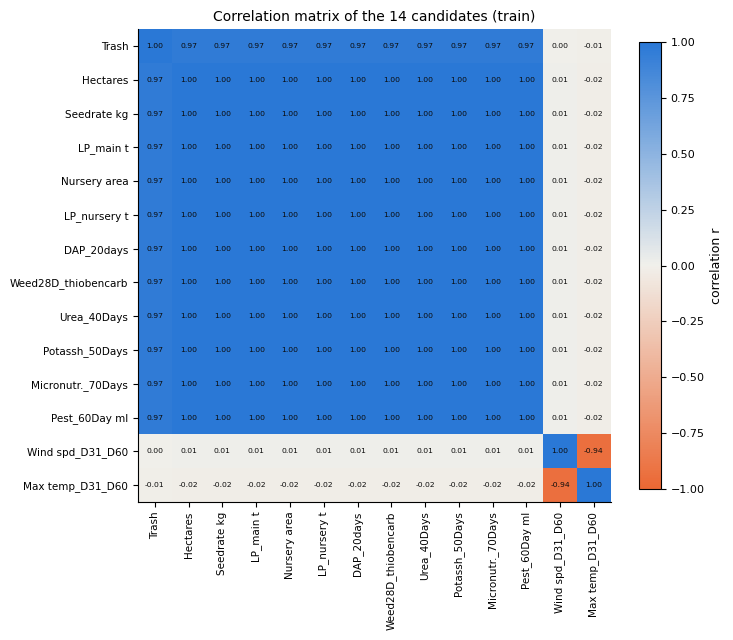

pairs with |r| >= 0.95: 66
  - inside Hectares + 10 inputs: 55 pairs, min |r| = 1.0000
  - Trash with one of those 11 columns: 11 pairs, |r| = 0.9668 to 0.9668
  - any other pair: 0
corr(Wind spd_D31_D60, Max temp_D31_D60) = -0.9444


In [60]:
from matplotlib.colors import LinearSegmentedColormap

W2 = ['Inst Wind Speed_D31_D60(in Knots)', 'Max temp_D31_D60']
cand = [TRASH, 'Hectares'] + INPUTS + W2
Rm = tr[cand].corr()
cmap = LinearSegmentedColormap.from_list('div', [ORANGE, '#f1f0eb', BLUE])
fig, ax = plt.subplots(figsize=(7.5, 6.5)); im = ax.imshow(Rm.values, cmap=cmap, vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(cand))); ax.set_xticklabels([short(c) for c in cand], rotation=90, fontsize=7.5)
ax.set_yticks(range(len(cand))); ax.set_yticklabels([short(c) for c in cand], fontsize=7.5)
for i in range(len(cand)):
    for j in range(len(cand)): ax.text(j, i, f'{Rm.values[i, j]:.2f}', ha='center', va='center', fontsize=5.5, color=INK)
plt.colorbar(im, fraction=0.04, label='correlation r'); ax.set_title(f'Correlation matrix of the {len(cand)} candidates (train)'); plt.tight_layout(); plt.show()

Ru = Rm.where(np.triu(np.ones(Rm.shape, dtype=bool), k=1)).stack()
strong = Ru[Ru.abs() >= 0.95]
SIZE = ['Hectares'] + INPUTS
inside = strong[[({a, b} <= set(SIZE)) for a, b in strong.index]]
with_trash = strong[[(TRASH in (a, b)) for a, b in strong.index]]
print(f'pairs with |r| >= 0.95: {len(strong)}')
print(f'  - inside Hectares + 10 inputs: {len(inside)} pairs, min |r| = {inside.abs().min():.4f}')
print(f'  - Trash with one of those 11 columns: {len(with_trash)} pairs, |r| = {with_trash.abs().min():.4f} to {with_trash.abs().max():.4f}')
print(f'  - any other pair: {len(strong) - len(inside) - len(with_trash)}')
print(f"corr(Wind spd_D31_D60, Max temp_D31_D60) = {Rm.loc[W2[0], W2[1]]:.4f}")

In [61]:
# ---- Exact relationships behind the high correlations ----
# 1) the 10 input columns divided by Hectares
ratio = pd.DataFrame({short(c): (tr[c] / tr['Hectares']).round(6) for c in INPUTS})      # round(6): removes floating-point noise only
print('1) INPUT columns divided by Hectares (1 distinct value = an exact constant per hectare):')
display(pd.DataFrame({'distinct per-ha values': ratio.nunique(), 'value per ha': ratio.iloc[0]}).T)

1) INPUT columns divided by Hectares (1 distinct value = an exact constant per hectare):


,Seedrate kg,LP_main t,Nursery area,LP_nursery t,DAP_20days,Weed28D_thiobencarb,Urea_40Days,Potassh_50Days,Micronutr._70Days,Pest_60Day ml
distinct per-ha values,1,1,1,1,1,1,1,1,1,1
value per ha,25,12.5,20,1,40,2,27.13,10.38,15,600


**Item 2: does `Trash` add anything beyond plot size?** `Trash` and `Hectares` are highly correlated, so the code below separates `Trash` into the part plot size explains and the part it doesn't, in 4 steps.

1. **Predict Trash from plot size only.** Fit one straight line through all training plots, ignoring variety (`np.polyfit`):

$$\widehat{\text{Trash}} = b_0 + b_1 \times \text{Hectares}$$

2. **leftover of each plot.** $\text{leftover} = \text{Trash}_{\text{actual}} - \widehat{\text{Trash}}$ (in bundles): the part of Trash that plot size does **not** explain.

3. **how much of Trash plot size explains.** Compare how much Trash varies before and after taking plot size away:

$$\text{explained} = 1 - \frac{\text{Var(leftover)}}{\text{Var(Trash)}}\quad\left(= r^2\right)$$

4. **leftover by variety.** The code shows the mean, min and max leftover for each variety. If the 3 ranges do not overlap, the leftover alone tells the varieties apart, so `Trash` is **not** redundant with `Hectares`.

**Example: a 3-ha plot.** Expected Trash = -2.01 + 90.89 × 3 = **270.7** bundles.

| Variety | Trash per ha | Actual Trash | Leftover |
|---|---|---|---|
| delux ponni | 80 | 240 | 240 - 270.7 = **-30.7** |
| CO_43 | 90 | 270 | 270 - 270.7 = **-0.7** |
| ponmani | 100 | 300 | 300 - 270.7 = **+29.3** |

Because each variety has a fixed Trash per hectare, its leftover grows with plot size: (its per-ha value - 90.89) × Hectares + 2.01. So the **min and max** come from the smallest (1 ha) and largest (6 ha) plots, and the **mean** is close to the leftover of an average-size plot.

In [62]:
# 2) Trash vs Hectares: how much of Trash does plot size explain, and what is left over?
b1, b0 = np.polyfit(tr['Hectares'], tr[TRASH], 1)
resid = tr[TRASH] - (b0 + b1 * tr['Hectares'])
print(f"2) corr(Trash, Hectares) = {tr[TRASH].corr(tr['Hectares']):.4f} -> Hectares explains {1 - resid.var() / tr[TRASH].var():.1%} of Trash's variance")
print('   the part of Trash NOT explained by Hectares (residual, bundles), by Variety:')
display(resid.groupby(tr[TARGET]).agg(['mean', 'min', 'max']).reindex(CLASSES))

2) corr(Trash, Hectares) = 0.9668 -> Hectares explains 93.5% of Trash's variance
   the part of Trash NOT explained by Hectares (residual, bundles), by Variety:


,mean,min,max
Variety,,,
CO_43,-1.2774,-3.3161,1.1221
delux ponni,-38.3606,-63.3161,-8.8779
ponmani,36.5377,11.1221,56.6839


In [63]:
# 3) the two weather candidates inside each agri-block
wb = tr.groupby('Agriblock')[W2].agg(['nunique', 'first']); wb.columns = [f'{short(a)} {b}' for a, b in wb.columns]
print('3) the 2 weather candidates inside each agri-block:'); display(wb)
pairs = tr.groupby(W2).Agriblock.nunique()
print(f'   distinct (wind speed, max temp) pairs: {len(pairs)} | agri-blocks per pair: {pairs.max()} -> the pair identifies the agri-block one-to-one:',
      len(pairs) == tr.Agriblock.nunique() and pairs.max() == 1)

3) the 2 weather candidates inside each agri-block:


,Wind spd_D31_D60 nunique,Wind spd_D31_D60 first,Max temp_D31_D60 nunique,Max temp_D31_D60 first
Agriblock,,,,
Chinnasalem,1,6,1,34
Cuddalore,1,10,1,30
Kallakurichi,1,6,1,32
Kurinjipadi,1,4,1,35
Panruti,1,12,1,30
Sankarapuram,1,12,1,28


   distinct (wind speed, max temp) pairs: 6 | agri-blocks per pair: 1 -> the pair identifies the agri-block one-to-one: True


### 10.1 Discussion — redundant features
| | Features | Evidence | Reading | Decision |
|---|---|---|---|---|
| **(a)** | `Hectares` + 10 input columns (`Seedrate`, `LP_Mainfield`, `Nursery area`, `LP_nurseryarea`, `DAP_20days`, `Weed28D_thiobencarb`, `Urea_40Days`, `Potassh_50Days`, `Micronutrients_70Days`, `Pest_60Day`) | 55 pairs with \|r\| = 1.0000; each input ÷ `Hectares` is one constant (e.g. `Seedrate` 25 kg/ha, `Pest_60Day` 600 ml/ha) | the same number written 11 ways: a fixed per-hectare amount, not 11 independent measurements | **keep `Hectares`, drop the 10 input columns** |
| **(b)** | `Trash` vs `Hectares` | r = 0.9668: bigger plots have more Trash, so Trash rises almost in step with `Hectares` (`Hectares` explains 93.5% of `Trash`) | Take away the part of Trash that plot size predicts. What is left is different for each variety and never overlaps: always below -9 bundles for delux ponni, between -3 and +1 for CO_43, always above +11 for ponmani. That leftover **is** the variety information, so the two columns are highly correlated but **not redundant**: dropping either one loses it | **keep both** |
| **(c)** | `Wind spd_D31_D60`, `Max temp_D31_D60` | Every plot in the same agri-block has the same wind speed and the same max temp, and the 6 (wind speed, max temp) pairs match the 6 agri-blocks one-to-one | So these 2 columns only tell **which agri-block** a plot is in. `Agriblock` itself is not related to `Variety` (chi-square p = 0.51): every block grows the 3 varieties in similar shares. | **drop both** |

**Summary:** of the 14 candidates, keep **2**: `Trash` and `Hectares`; drop **12**.

# 11 · Feature extraction
**Creating a few new features from old ones**. Two tools are tried on the 2 remaining features (`Trash`, `Hectares`):
* a domain-knowledge feature
* Principal Component Analysis (PCA)

### 11.1 Domain-knowledge feature: Trash per hectare
Bigger plots produce more Trash, so raw `Trash` mixes two things: plot size and the variety. Dividing by plot size removes the size part and leaves an amount **per hectare**:

$$\text{Trash\_per\_ha} = \frac{\text{Trash}}{\text{Hectares}}$$

**Assumption:** Trash grows in proportion to plot area.

,count,mean,std,min,max
Variety,,,,,
CO_43,428,90,0,90,90
delux ponni,582,80,0,80,80
ponmani,626,100,0,100,100


ANOVA F: raw Trash = 60.7 | Trash_per_ha = inf  (variance within each variety = 0, so F = between / within is infinite)


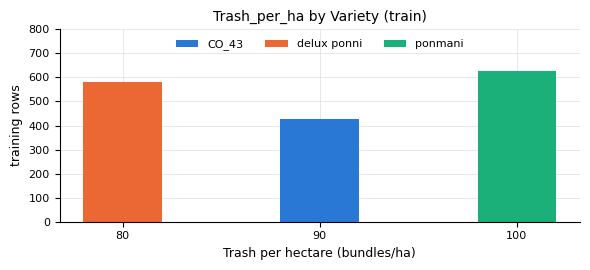

In [64]:
TPH = 'Trash_per_ha'
def add_tph(d):
    d = d.copy(); d[TPH] = d[TRASH] / d['Hectares']; return d
tr = add_tph(tr)

display(tr.groupby(TARGET)[TPH].agg(['count', 'mean', 'std', 'min', 'max']).reindex(CLASSES))

with np.errstate(divide='ignore', invalid='ignore'):
    F_tph = f_classif(tr[[TPH]], tr[TARGET])[0][0]
F_raw = f_classif(tr[[TRASH]], tr[TARGET])[0][0]
print(f'ANOVA F: raw Trash = {F_raw:.1f} | Trash_per_ha = {F_tph}  (variance within each variety = 0, so F = between / within is infinite)')

fig, ax = plt.subplots(figsize=(6, 2.8))
vals = sorted(tr[TPH].unique())
for k, col in zip(CLASSES, cols3):
    cnt = tr.loc[tr[TARGET] == k, TPH].value_counts().reindex(vals, fill_value=0)
    ax.bar(cnt.index, cnt.values, width=4, color=col, label=k)
ax.set(xticks=vals, xlabel='Trash per hectare (bundles/ha)', ylabel='training rows', title='Trash_per_ha by Variety (train)', ylim=(0, 800)); ax.legend(ncol=3, loc='upper center')
plt.tight_layout(); plt.show()

### 11.2 Principal component analysis (PCA)

**Assumptions and limits:**
1. Structure must be **linear**.
2. PCA is **unsupervised**, so a high-variance PC need not predict the target, and a low-variance PC may.
3. PCA is **scale-sensitive**, so features are **standardised first** (mean 0, SD 1).

,variance explained %,loading on Trash,loading on Hectares,ANOVA F vs Variety
PC1,98.3398,0.7071,0.7071,17.665
PC2,1.6602,0.7071,-0.7071,"4,736.5"


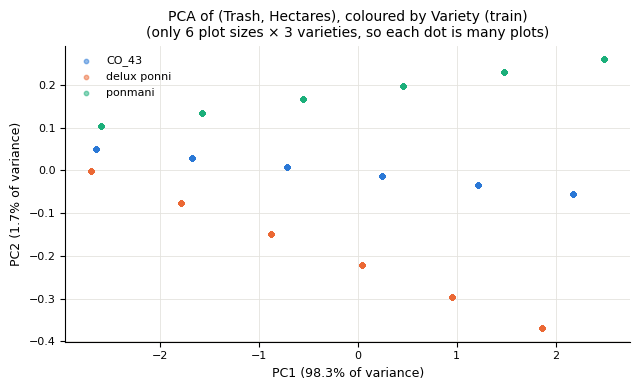

In [65]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

PCOLS = [TRASH, 'Hectares']
sc_p = StandardScaler().fit(tr[PCOLS]); pca = PCA(random_state=SEED).fit(sc_p.transform(tr[PCOLS]))
Zp = pca.transform(sc_p.transform(tr[PCOLS]))
Fp = f_classif(Zp, tr[TARGET])[0]
display(pd.DataFrame({'variance explained %': pca.explained_variance_ratio_ * 100,
                      'loading on Trash': pca.components_[:, 0], 'loading on Hectares': pca.components_[:, 1],
                      'ANOVA F vs Variety': Fp}, index=['PC1', 'PC2']))

fig, ax = plt.subplots(figsize=(6.5, 4))
for k, col in zip(CLASSES, cols3):
    s = (tr[TARGET] == k).values; ax.scatter(Zp[s, 0], Zp[s, 1], s=10, alpha=0.5, color=col, label=k)
ax.set(xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)', ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)',
       title='PCA of (Trash, Hectares), coloured by Variety (train)\n(only 6 plot sizes × 3 varieties, so each dot is many plots)'); ax.legend()
plt.tight_layout(); plt.show()

### 11.3 Discussion — feature extraction
| | Tool | Decision | Reason |
|---|---|---|---|
| **(a)** | `Trash_per_ha` | **add; use as the model's feature** | In train it takes exactly one value per variety: **80** (delux ponni), **90** (CO_43), **100** (ponmani), with SD = 0 inside each variety, so ANOVA F = ∞ (raw `Trash`: F = 60.7). One easy-to-read column ("how much Trash per hectare") does what `Trash` + `Hectares` did together |
| **(b)** | PCA on (`Trash`, `Hectares`) | **not used** | PC1 holds 98.3% of the variance but hardly separates the varieties (F = 17.7); PC2 holds only 1.7% of the variance but separates them strongly (F = 4,736). The usual "keep ~90% of variance" rule would keep PC1 and drop PC2, losing the variety information. Keeping both PCs is only a rotation of the same 2 features, so nothing is gained, and `Trash_per_ha` already captures that information in one column |

**Summary:** the model uses **1 feature, `Trash_per_ha`**. The raw pair `Trash` + `Hectares` is kept as a comparison feature set.

# 12 · Data pre-processing
**Feature sets carried forward:**

| Name | Features | Why |
|---|---|---|
| **MAIN** | `Trash_per_ha` | the one feature chosen in feature extraction |
| **RAW** (comparison) | `Trash`, `Hectares` | the 2 features kept after selection and redundancy analysis, before feature extraction |

**Steps:**
1. **Create `Trash_per_ha` on test** with the same formula as on train.
2. **No one-hot encoding needed:** no categorical predictor is left.
3. **Standardise** every numeric feature. Without scaling, a feature's weight depends on its units, the regularisation penalty in scikit-learn's logistic regression hits the features unequally, and the iterative solver converges more slowly.
4. **Fit the scaler on TRAIN only**, then only `.transform()` test. The scaler sits inside a `Pipeline`, so during cross-validation it is re-fit on each training fold.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

train, test = add_tph(train), add_tph(test)                       
FEATS = {'MAIN': [TPH], 'RAW': [TRASH, 'Hectares']}

def make_pre(cols):
    return ColumnTransformer([('num', StandardScaler(), cols)])   

ytr, yte = train[TARGET].values, test[TARGET].values              
for name, cols in FEATS.items():
    pre = make_pre(cols).fit(train)                               
    sc = pre.named_transformers_['num']
    print(f'{name:4s} design: train {pre.transform(train).shape}, test {pre.transform(test).shape} | '
          + ' | '.join(f'{short(c)}: train mean {m:.2f}, SD {s:.2f}' for c, m, s in zip(cols, sc.mean_, sc.scale_)))
print('\nclass labels:', sorted(set(ytr)), '| train', len(ytr), '| test', len(yte))

MAIN design: train (1636, 1), test (702, 1) | Trash_per_ha: train mean 90.27, SD 8.59
RAW  design: train (1636, 2), test (702, 2) | Trash: train mean 337.71, SD 134.69 | Hectares: train mean 3.74, SD 1.43

class labels: ['CO_43', 'delux ponni', 'ponmani'] | train 1636 | test 702


# 13 · Model building and training
### 13.1 Models fit
All three use **One-vs-Rest logistic regression**, with the scaler inside the pipeline.

| Model | Features | 
|---|---|
| `M1_MAIN` | `Trash_per_ha` | 
| `M2_RAW` | `Trash`, `Hectares` | 
| `M3_ALL` | all 44 candidate predictors (37 numeric standardised + 7 categorical one-hot encoded) | 

### 13.2 Choosing the regularisation strength C (5-fold CV, train only)
`C` controls the L2 penalty: 
- small C = strong penalty (weights pushed towards 0)
- large C = weak penalty. 

Each model is scored with stratified 5-fold cross-validation **inside `train`** (test still untouched), using accuracy. Rule: take the **smallest C that reaches the best CV score** (the simplest model that fits as well as any).

,M1_MAIN,M2_RAW,M3_ALL
C,,,
0.01,0.7384,0.6314,0.7231
0.1,1,0.7213,0.7573
1,1,0.9364,0.9505
10,1,0.9749,0.9872
100,1,1,0.9982
"1,000",1,1,1


chosen C (smallest C with the best CV accuracy): {'M1_MAIN': 0.1, 'M2_RAW': 100.0, 'M3_ALL': 1000.0}


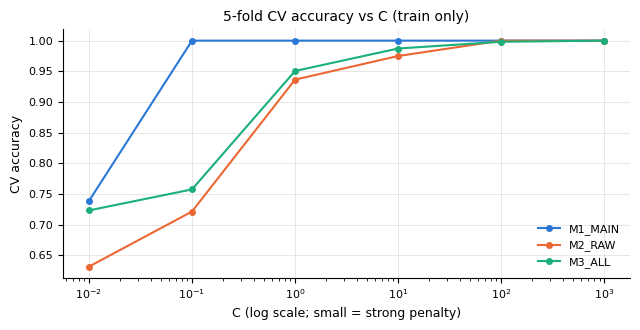

In [67]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedKFold, cross_val_score

pre_all = lambda: ColumnTransformer([('num', StandardScaler(), NUM), ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), CAT)])
PRE = {'M1_MAIN': lambda: make_pre(FEATS['MAIN']), 'M2_RAW': lambda: make_pre(FEATS['RAW']), 'M3_ALL': pre_all}
def ovr_model(name, C=1.0):
    return Pipeline([('pre', PRE[name]()), ('clf', OneVsRestClassifier(LogisticRegression(C=C, max_iter=10000)))])

CS = [0.01, 0.1, 1, 10, 100, 1000]
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
cvC = pd.DataFrame({name: [cross_val_score(ovr_model(name, C), train, ytr, cv=skf, scoring='accuracy').mean() for C in CS] for name in PRE}, index=CS)
cvC.index.name = 'C'
display(cvC)
best_C = {name: float(cvC.index[np.isclose(cvC[name], cvC[name].max())].min()) for name in PRE}
print('chosen C (smallest C with the best CV accuracy):', best_C)

fig, ax = plt.subplots(figsize=(6.5, 3.4))
for name, col in zip(PRE, [BLUE, ORANGE, AQUA]): ax.plot(CS, cvC[name], '-o', color=col, ms=4, label=name)
ax.set(xscale='log', xlabel='C (log scale; small = strong penalty)', ylabel='CV accuracy', title='5-fold CV accuracy vs C (train only)'); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

### 13.3 Final fit and over-fitting check
Each model is re-fit on the whole training set with its chosen `C`. Comparing train, CV and test scores checks for over-fitting (train much better than CV/test).

In [68]:
from sklearn.metrics import accuracy_score, recall_score

final, rows = {}, []
for name in PRE:
    m = ovr_model(name, best_C[name]).fit(train, ytr); final[name] = m
    cv_acc = cross_val_score(ovr_model(name, best_C[name]), train, ytr, cv=skf, scoring='accuracy')
    p_tr, p_te = m.predict(train), m.predict(test)
    rows.append(dict(model=name, C=best_C[name], train_acc=accuracy_score(ytr, p_tr), CV_acc_mean=cv_acc.mean(), CV_acc_sd=cv_acc.std(),
                     test_acc=accuracy_score(yte, p_te),
                     **{f'test_recall_{k}': r for k, r in zip(CLASSES, recall_score(yte, p_te, labels=CLASSES, average=None))}))
res_tab = pd.DataFrame(rows).set_index('model')
display(res_tab)

# same three models at the scikit-learn default C = 1, for comparison
rows1 = []
for name in PRE:
    m1 = ovr_model(name, 1.0).fit(train, ytr); p = m1.predict(test)
    rows1.append(dict(model=name, test_acc=accuracy_score(yte, p),
                      **{f'test_recall_{k}': r for k, r in zip(CLASSES, recall_score(yte, p, labels=CLASSES, average=None))}))
print('for comparison, with the default C = 1:'); display(pd.DataFrame(rows1).set_index('model'))

,C,train_acc,CV_acc_mean,CV_acc_sd,test_acc,test_recall_CO_43,test_recall_delux ponni,test_recall_ponmani
model,,,,,,,,
M1_MAIN,0.1,1,1,0,0.9986,1,0.996,1
M2_RAW,100,1,1,0,0.9986,1,0.996,1
M3_ALL,"1,000",1,1,0,0.9986,1,0.996,1


for comparison, with the default C = 1:


,test_acc,test_recall_CO_43,test_recall_delux ponni,test_recall_ponmani
model,,,,
M1_MAIN,0.9986,1,0.996,1
M2_RAW,0.9302,0.7377,0.996,1
M3_ALL,0.9587,0.847,0.996,1


In [69]:
# ---- How One-vs-Rest decides with one feature: probability from each binary model at the 3 values of Trash_per_ha ----
m = final['M1_MAIN']; grid_x = pd.DataFrame({TPH: [80.0, 90.0, 100.0]})
P = pd.DataFrame(np.column_stack([e.predict_proba(m.named_steps['pre'].transform(grid_x))[:, 1] for e in m.named_steps['clf'].estimators_]),
                 index=[f'Trash_per_ha = {v:.0f}' for v in grid_x[TPH]], columns=[f'p({k})' for k in m.named_steps['clf'].classes_])
P['predicted (highest p)'] = P.idxmax(axis=1).str[2:-1]
display(P)
print('weights w (standardised feature):', {str(k): round(float(e.coef_[0, 0]), 3) for k, e in zip(m.named_steps['clf'].classes_, m.named_steps['clf'].estimators_)})

,p(CO_43),p(delux ponni),p(ponmani),predicted (highest p)
Trash_per_ha = 80,0.2711,0.9365,0.0006,delux ponni
Trash_per_ha = 90,0.2618,0.0857,0.0868,CO_43
Trash_per_ha = 100,0.2527,0.0006,0.9402,ponmani


weights w (standardised feature): {'CO_43': -0.041, 'delux ponni': -4.344, 'ponmani': 4.388}


### 13.4 Logistic-regression assumption checks, on `M1_MAIN`
| Assumption | Check |
|---|---|
| Linear relationship between the features and the target (the log-odds) | `Trash_per_ha` takes 3 values, one per variety, so each binary model only has to put a threshold between them |
| Little or no multicollinearity | `M1_MAIN` has a single feature, so there is none. (`M2_RAW`: r(`Trash`, `Hectares`) = 0.97) |
| No high-leverage points or influential outliers | no value with \|z\| > 3 in the outlier analysis |
| No auto-correlation (independent rows) | assumed: rows have no order, date or ID, so it cannot be checked |

### 13.5 Discussion — model training
| | Finding | Reason |
|---|---|---|
| **(a)** | The `CO_43 vs rest` model is almost flat (w = -0.04): it gives p(CO_43) ≈ 0.26 to every plot | CO_43 is the **middle** value of `Trash_per_ha` (90, between 80 and 100). One binary logistic model draws a single threshold, so it can separate below from above but not middle from both sides. OvR still works because the prediction is the **highest** probability: at 90 the other two models both give about 0.09, so CO_43 (0.26) wins; at 80 or 100 one of the other models gives about 0.94 |
| **(b)** | `M2_RAW` and `M3_ALL` need a weak penalty (C = 100 and 1000). At the default C = 1 they reach only 0.930 and 0.959 test accuracy, with CO_43 recall 0.74 and 0.85 | Without `Trash_per_ha`, the model has to build "Trash relative to plot size" itself from `Trash` and `Hectares`, which needs large weights; a strong penalty shrinks them and CO_43 (the middle class) is lost first. `M1_MAIN` already reaches CV accuracy = 1.0 at C = 0.1 |
| **(c)** | After choosing C, all three models give the same result: train and CV accuracy 1.0, test accuracy 0.9986 | No over-fitting: the test score is as high as the train and CV scores |

**Decision: `M1_MAIN` (`Trash_per_ha`, C = 0.1) is the primary model.**

# 14 · Results and presentation
**Final model:** `M1_MAIN`: One-vs-Rest logistic regression on `Trash_per_ha` (standardised), C = 0.1, fit on `train` and evaluated once on `test`.

**Metrics:** for each variety, treated as "positive" against the other two:

| Metric | Formula | Question it answers |
|---|---|---|
| **Accuracy** | correct predictions / all predictions | what share of plots get the right variety? |
| **Precision** | TP / (TP + FP) | when the model says "variety k", how often is it right? |
| **Recall** | TP / (TP + FN) | of the plots that really are variety k, how many does it find? |
| **F1** | 2 · precision · recall / (precision + recall) | one score combining both |

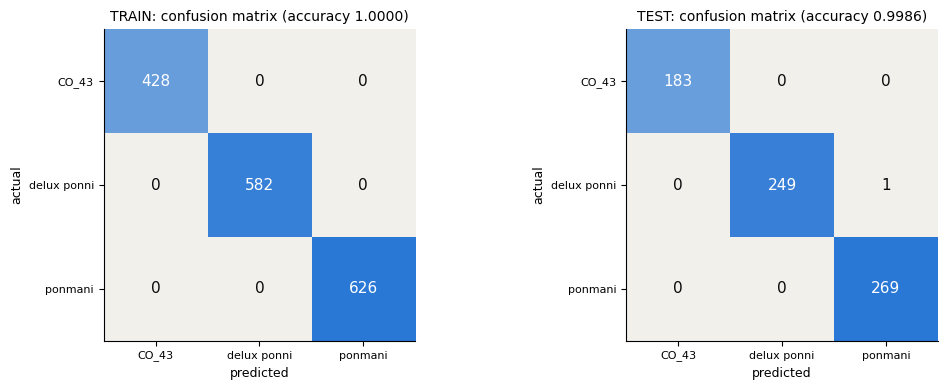

TEST set, per variety:


,precision,recall,F1,test rows
CO_43,1,1,1,183
delux ponni,1,0.996,0.998,250
ponmani,0.9963,1,0.9981,269


accuracy: train 1.0000 | test 0.9986


In [70]:
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

m_final = final['M1_MAIN']
pred_tr, pred_te = m_final.predict(train), m_final.predict(test)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (y_true, y_pred, ttl) in zip(ax, [(ytr, pred_tr, 'TRAIN'), (yte, pred_te, 'TEST')]):
    cm = confusion_matrix(y_true, y_pred, labels=CLASSES)
    a.imshow(cm, cmap=LinearSegmentedColormap.from_list('b', ['#f1f0eb', BLUE])); a.grid(False)
    for i in range(3):
        for j in range(3): a.text(j, i, cm[i, j], ha='center', va='center', fontsize=11, color='white' if cm[i, j] > cm.max() / 2 else INK)
    a.set(xticks=range(3), yticks=range(3), xticklabels=CLASSES, yticklabels=CLASSES, xlabel='predicted', ylabel='actual',
          title=f'{ttl}: confusion matrix (accuracy {accuracy_score(y_true, y_pred):.4f})')
plt.tight_layout(); plt.show()

pr, rc, f1, sup = precision_recall_fscore_support(yte, pred_te, labels=CLASSES)
met = pd.DataFrame({'precision': pr, 'recall': rc, 'F1': f1, 'test rows': sup}, index=CLASSES)
print('TEST set, per variety:'); display(met)
print(f'accuracy: train {accuracy_score(ytr, pred_tr):.4f} | test {accuracy_score(yte, pred_te):.4f}')

### 14.1 The misclassified test plot

In [71]:
wrong = test[pred_te != yte]
proba_wrong = pd.DataFrame(m_final.predict_proba(wrong), index=wrong.index, columns=[f'p({k})' for k in m_final.classes_])
display(pd.concat([wrong[['Agriblock', 'Hectares', TRASH, TPH, YIELD, TARGET]], pd.Series(pred_te[pred_te != yte], index=wrong.index, name='predicted'), proba_wrong], axis=1))

# every other plot that matches it on all 43 features except Paddy yield
F43 = [c for c in FEATURES if c != YIELD]
for i in wrong.index:
    twins = df[(df[F43] == df.loc[i, F43]).all(axis=1)].drop(index=i)
    print(f'row {i}: {len(twins)} other plots share all 43 features except yield ->')
    display(twins[[TARGET, YIELD]].assign(in_train=twins.index.isin(train.index)))

,Agriblock,Hectares,Trash(in bundles),Trash_per_ha,Paddy yield(in Kg),Variety,predicted,p(CO_43),p(delux ponni),p(ponmani)
2,Panruti,6,600,100,36300,delux ponni,ponmani,0.2117,0.0005,0.7878


row 2: 4 other plots share all 43 features except yield ->


,Variety,Paddy yield(in Kg),in_train
26,ponmani,33462,True
32,ponmani,35040,True
92,ponmani,35448,True
134,ponmani,36552,True


### 14.2 ROC curve and AUC (one curve per variety, One-vs-Rest)
Each curve uses the model's probability for that variety and varies the decision threshold; AUC = 1 means the probabilities rank every plot of that variety above every other plot.

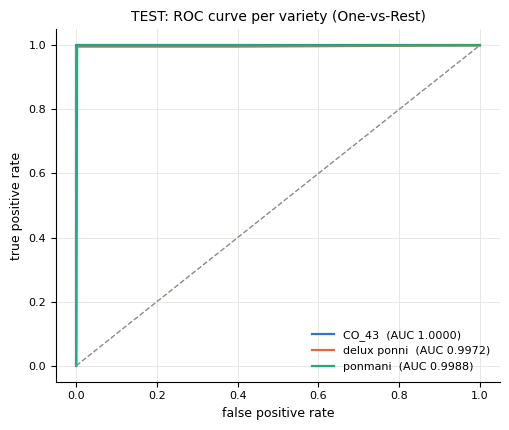

In [72]:
from sklearn.metrics import roc_curve, roc_auc_score

P_te = m_final.predict_proba(test)
fig, ax = plt.subplots(figsize=(5.2, 4.4))
aucs = {}
for i, (k, col) in enumerate(zip(m_final.classes_, cols3)):
    yk = (yte == k).astype(int); fpr, tpr, _ = roc_curve(yk, P_te[:, i]); aucs[k] = roc_auc_score(yk, P_te[:, i])
    ax.plot(fpr, tpr, color=col, lw=1.6, label=f'{k}  (AUC {aucs[k]:.4f})')
ax.plot([0, 1], [0, 1], color=GREY, ls='--', lw=1)
ax.set(xlabel='false positive rate', ylabel='true positive rate', title='TEST: ROC curve per variety (One-vs-Rest)'); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

### 14.3 What the model learned

decision rule learned on train (Trash_per_ha, bundles/ha):
  below 87.3 -> delux ponni | 87.3 to 92.5 -> CO_43 | above 92.5 -> ponmani


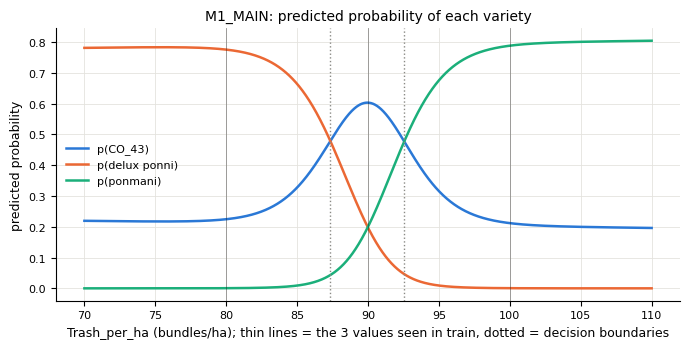

In [73]:
xg = pd.DataFrame({TPH: np.linspace(70, 110, 4001)})
Pg, cg = m_final.predict_proba(xg), m_final.predict(xg)
cut = np.where(cg[1:] != cg[:-1])[0]
print('decision rule learned on train (Trash_per_ha, bundles/ha):')
print(f'  below {xg[TPH].values[cut[0]]:.1f} -> {cg[0]} | {xg[TPH].values[cut[0]]:.1f} to {xg[TPH].values[cut[1]]:.1f} -> {cg[cut[0] + 1]} | above {xg[TPH].values[cut[1]]:.1f} -> {cg[-1]}')

fig, ax = plt.subplots(figsize=(7, 3.6))
for i, (k, col) in enumerate(zip(m_final.classes_, cols3)): ax.plot(xg[TPH], Pg[:, i], color=col, lw=1.8, label=f'p({k})')
for c in cut: ax.axvline(xg[TPH].values[c], color=GREY, ls=':', lw=1)
for v in (80, 90, 100): ax.axvline(v, color=INK, lw=0.6, alpha=0.4)
ax.set(xlabel='Trash_per_ha (bundles/ha); thin lines = the 3 values seen in train, dotted = decision boundaries', ylabel='predicted probability',
       title='M1_MAIN: predicted probability of each variety'); ax.legend(loc='center left', fontsize=8)
plt.tight_layout(); plt.show()

### 14.4 Discussion — results analysis
| | Finding | Reading |
|---|---|---|
| **(a) Scores** | Test accuracy **0.9986** ; train 1.0. Precision and recall are ≥ 0.996 for every variety | No over-fitting |
| **(b) The one error** | delux ponni, 6 ha, Trash 600, so **100 bundles/ha** (the ponmani value); predicted ponmani (p = 0.79) | 4 ponmani training plots share **all 43 other features**, and its yield (36,300 kg) is inside their range (33,462-36,552 kg). Nothing in the data tells it apart from a ponmani plot, so no model built on these features could get it right. |
| **(c) ROC / AUC** | AUC = 1.0000 (CO_43), 0.9972 (delux ponni), 0.9988 (ponmani) | Below 1 only because of that one row |
| **(d) Learned rule** | below **87.3** bundles/ha → delux ponni; **87.3-92.5** → CO_43; above **92.5** → ponmani | The boundaries fall roughly halfway between the 3 values seen in train (80, 90, 100) |
| **(e) Probability curves** | p(CO_43) is a bump that peaks at 90, even though the CO_43-vs-rest model is almost flat | One-vs-Rest divides each binary model's probability by the sum of the 3, so CO_43's share is largest where the other two models are both low. The probabilities are moderate (max ≈ 0.8) because C = 0.1 shrinks the weights; the prediction only uses which probability is highest |

# 15 · Discussion
### 15.1 What if `Trash` is not available
Assumption A1 places the prediction **after harvest**, so `Trash` and `Paddy yield` are known. If the model were used earlier (e.g. to identify the variety during the season), those harvest columns would not exist yet. Two extra models check how much the result depends on them, with the same pipeline and the same rule for choosing C:

| Model | Features |
|---|---|
| `M4_NO_TRASH` | all 44 candidates **except `Trash`** (43) |
| `M5_PRE_HARVEST` | all 44 candidates **except `Trash` and `Paddy yield`** (42) |

In [74]:
def ovr_without(drop, C):
    num = [c for c in NUM if c not in drop]
    pre = ColumnTransformer([('num', StandardScaler(), num), ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), CAT)])
    return Pipeline([('pre', pre), ('clf', OneVsRestClassifier(LogisticRegression(C=C, max_iter=10000)))])

rows = []
for name, drop in {'M4_NO_TRASH': [TRASH], 'M5_PRE_HARVEST': [TRASH, YIELD]}.items():
    cv = pd.Series({C: cross_val_score(ovr_without(drop, C), train, ytr, cv=skf, scoring='accuracy').mean() for C in CS})
    C_best = float(cv.index[np.isclose(cv, cv.max())].min())
    m = ovr_without(drop, C_best).fit(train, ytr); p = m.predict(test)
    rows.append(dict(model=name, C=C_best, CV_acc=cv.max(), test_acc=accuracy_score(yte, p),
                     **{f'test_recall_{k}': r for k, r in zip(CLASSES, recall_score(yte, p, labels=CLASSES, average=None))}))
rows.append(dict(model='M1_MAIN (for reference)', C=best_C['M1_MAIN'], CV_acc=res_tab.loc['M1_MAIN', 'CV_acc_mean'], test_acc=res_tab.loc['M1_MAIN', 'test_acc'],
                 **{f'test_recall_{k}': res_tab.loc['M1_MAIN', f'test_recall_{k}'] for k in CLASSES}))
display(pd.DataFrame(rows).set_index('model'))
print(f"for reference, always predicting the largest class ('ponmani') is right on {np.mean(yte == 'ponmani'):.1%} of test plots")

,C,CV_acc,test_acc,test_recall_CO_43,test_recall_delux ponni,test_recall_ponmani
model,,,,,,
M4_NO_TRASH,"1,000",0.3942,0.3974,0,0.496,0.5762
M5_PRE_HARVEST,10,0.3777,0.3917,0,0.268,0.7732
M1_MAIN (for reference),0.1,1,0.9986,1,0.996,1


for reference, always predicting the largest class ('ponmani') is right on 38.3% of test plots


**Reading:** without `Trash`, accuracy falls from 0.999 to about **0.40**, close to the 38.3% from always guessing `ponmani`, and **CO_43 is never predicted** (recall 0). Removing `Paddy yield` as well changes nothing. So **the whole result rests on one harvest measurement**: none of the other 42-43 columns (plot size, inputs, location, soil, nursery, weather, yield) can tell the varieties apart.

### 15.2 Accurate, Over-fittin, Practicle and Important Features
| Question | Answer |
|---|---|
| **Accurate** | After choosing C, `M1_MAIN`, `M2_RAW` and `M3_ALL` all reach test accuracy **0.9986**. At the default C = 1, `M2_RAW` (0.930) and `M3_ALL` (0.959) are worse, mainly on CO_43. **`M1_MAIN` is the best choice**: same accuracy with 1 feature, and it works for any C ≥ 0.1. Without `Trash` (`M4`, `M5`) accuracy drops to about 0.40 |
| **Over-fitting** | **No Over-fitting** `M1_MAIN` Train = CV = 1.0 and test = 0.9986. |
| **Practicle?** | **Only within its assumptions, and with caution.** (1) It needs `Trash` and `Hectares`, so it only works **after harvest** (A1); before harvest it is no better than guessing. (2) It relies on each variety leaving an exact amount of Trash per hectare (80 / 90 / 100). Real fields would vary around these values, so accuracy on real data would be lower than 0.9986. (3) It only knows these 3 varieties (A6), plot sizes of 1-6 ha and 6 agri-blocks in one region |
| **Important Features** | **`Trash_per_ha` alone is sufficient** (equivalently, `Trash` together with `Hectares`).|

### 15.3 About the dataset
* Trash per hectare is exactly 80, 90 or 100 for every plot but one, set by the variety. Real straw or residue amounts would vary from field to field.
* All 10 inputs are a fixed amount per hectare, and weather is identical for every plot in an agri-block.
* Together this suggests the file follows fixed per-hectare rules, or was generated from them (A5). The model has essentially learned the rule used to make `Trash`, so the near-perfect score describes this dataset, not how well rice varieties can be identified on real farms.
* The workflow itself (leakage-safe split, EDA, filter-based selection, redundancy analysis, feature extraction, cross-validated C, error analysis) is what would be applied to real data.

# 16 · Conclusion
**Workflow** (everything learned on `train` only; `test` used once, for the final results):
* **Data quality** 
    - 451 exact duplicate rows (16.2%) removed
    - no missing values
    - no rows removed as outliers
* **Split** 
    - stratified 70/30 on `Variety`, before any analysis.
* **Feature selection** 
    - 44 candidates 
    - 14 after filter methods
    - 2 after redundancy analysis (`Trash`, `Hectares`)
* **Feature extraction** 
    - `Trash_per_ha` created
    - PCA not used, because it would drop the component that carries the variety information.
* **Model** 
    - One-vs-Rest logistic regression, with C chosen by 5-fold cross-validation on `train`.

* **Final model** 
    - `M1_MAIN`
    - One-vs-Rest logistic regression on 
        - $x$ = `Trash_per_ha` (bundles/ha)
        - C = 0.1 
        
Each binary model gives the probability of its variety:
* delux ponni: $\;p_1(x) = \sigma(43.156 - 0.5058\,x)$
* CO_43: $\;p_2(x) = \sigma(-0.606 - 0.0048\,x)$
* ponmani: $\;p_3(x) = \sigma(-48.333 + 0.5109\,x)$

$$\sigma(z) = \frac{1}{1 + e^{-z}}, \qquad \hat{y} = \arg\max_{k}\; p_k(x)$$

The weights are the fitted ones, converted from the standardised scale $\big(z = \frac{x - 90.27}{8.59}\big)$ back to bundles/ha. 

The predicted variety changes at 
- $x$ = 87.3 (delux ponni --> CO_43)
- $x$ = 92.5 (CO_43 --> ponmani)

Test accuracy 0.9986 , with no over-fitting.

limitation: the result depends entirely on `Trash`, a harvest measurement. Without it, accuracy falls to about 0.40, no better than guessing. And in this file Trash per hectare is fixed exactly by the variety, so the near-perfect score describes this dataset, not how well rice varieties could be identified on real farms.